> **Local copy for a Windows PC with an NVIDIA GPU.** Only the environment changed: it checks the GPU, reads the dataset from the Roboflow zip in `C:\C389_local\data` (no key needed), writes to `C:\C389_local\runs\CA1_luggage`, and loads data in the main process on Windows. The tuning settings, seeds and everything else are exactly as in the Colab notebook.

# CA1: luggage_left and luggage_right

Built from the Lesson 3 and Lesson 5A notebooks and uses the same recipe: Roboflow
download, `data.yaml` fix, per class instance counts, `yolo26n.pt`, 100 epochs,
`fliplr=0.0`, per class results and the saved artifacts. Run the cells in order.

## What is different from Lesson 3

1. **Four classes.** `person_left`, `person_right`, `luggage_left` and `luggage_right`. The
   class order comes from Roboflow (alphabetical) and the notebook reads classes by name,
   so the order does not matter.
2. **An optional re-split by scene (Section 4).** Roboflow splits image by image. Every
   scene in this dataset has several near-identical frames, so a random split puts
   copies of the same scene in train and in test and the score looks far better than the
   model really is. Section 4 keeps every scene in one split only.
3. **A per angle check (Section 8)**, because the dataset was shot from 6 angles and the
   question for the report is whether the model works on all of them.

## Before you run

- Drive folder: `My Drive/C389` (as in the Colab Folder Setup Guide).
- Runtime, Change runtime type, **T4 GPU**.
- Roboflow: generate the version with **no Roboflow augmentation** (Ultralytics augments
  during training). Augmented copies made by Roboflow share a scene with the original and
  would leak into the test split.

---

## 1. Setup

In [3]:
   %pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
LOCAL_ROOT = r"C:\C389_local"   # data\ holds the Roboflow zip, runs\ holds everything this notebook writes
ULTRALYTICS_VERSION = "8.4.120"   # pinned, as in Lesson 3
RUNNING_ON_COLAB = False

import glob
import importlib.metadata
import os

import torch

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch cannot see the GPU. Install the CUDA build of PyTorch from pytorch.org, "
                       "then restart this notebook.")
print("GPU:", torch.cuda.get_device_name(0),
      "(%.1f GB)" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
try:
    installed = importlib.metadata.version("ultralytics")
    if installed != ULTRALYTICS_VERSION:
        print("WARNING: ultralytics %s is installed, this notebook was written for %s.\n"
              "         Run: pip install ultralytics==%s" % (installed, ULTRALYTICS_VERSION, ULTRALYTICS_VERSION))
except importlib.metadata.PackageNotFoundError:
    raise RuntimeError("Run: pip install ultralytics==%s roboflow" % ULTRALYTICS_VERSION)

# Windows notebooks can crash when data loading uses extra processes, so load in the main process there.
WORKERS = 0 if os.name == "nt" else 8
print("LOCAL_ROOT:", LOCAL_ROOT, "  workers:", WORKERS)

GPU: NVIDIA GeForce RTX 3060 (12.9 GB)
LOCAL_ROOT: C:\C389_local   workers: 0


In [5]:
import json
import os
import random
import re
import shutil
import zipfile
from collections import Counter, defaultdict

import torch
from ultralytics import YOLO

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

print("torch :", torch.__version__)
print("GPU   :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
if not torch.cuda.is_available():
    print("No GPU. In Colab: Runtime, Change runtime type, T4 GPU.")

torch : 2.14.1+cu126
GPU   : NVIDIA GeForce RTX 3060


In [6]:
def find_column(columns, required_terms):
    for column in columns:
        normalised = column.lower().replace(" ", "")
        if all(term.lower().replace(" ", "") in normalised for term in required_terms):
            return column
    return None


def clean_results_csv(csv_path):
    table = pd.read_csv(csv_path)
    table.columns = [column.strip() for column in table.columns]
    return table

In [7]:
PROJECT_ROOT = LOCAL_ROOT

WORK_DIR = os.path.join(PROJECT_ROOT, "runs", "CA1_luggage")
os.makedirs(WORK_DIR, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)   # C:\\C389_local
print("WORK_DIR    :", WORK_DIR)

PROJECT_ROOT: C:\C389_local
WORK_DIR    : C:\C389_local\runs\CA1_luggage


---

## 2. The dataset

Two ways in, in this order:

1. **Roboflow download code.** Paste it between the triple quotes and **delete the API
   key** so the line reads `api_key=""`. The cell asks for the key when it runs, or reads
   `ROBOFLOW_API_KEY` from Colab Secrets.
2. **A copy on Drive.** If the triple quotes are empty, the cell looks for either an
   unzipped export at `C389/data/luggage/` (holding `data.yaml`, `train`, `valid`, `test`)
   or a zip at `C389/data/luggage.zip`.

In [8]:
import re
from getpass import getpass

ROBOFLOW_CODE = """
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("isaacs-workspace-evloh").project("people-counting-activity-with-tw")
version = project.version(1)
dataset = version.download("yolo26")

"""

YOLO_FORMATS = ("yolov8", "yolo26", "yolov11", "yolov12", "yolov9", "yolov5")


def read_roboflow_code(code):
    """Workspace, project, version and format from Roboflow's code, or None."""
    if not code.strip():
        return None
    key = re.search(r"api_key\s*=\s*[\"']([^\"']*)[\"']", code)
    if key and key.group(1).strip():
        raise ValueError("The pasted code still holds your private API key. "
                         "Delete it so the line reads api_key=\"\", then run again.")
    found = {}
    for name, pattern in (("workspace", r"\.workspace\(\s*[\"']([^\"']+)[\"']"),
                          ("project", r"\.project\(\s*[\"']([^\"']+)[\"']"),
                          ("version", r"\.version\(\s*(\d+)\s*\)"),
                          ("format", r"\.download\(\s*[\"']([^\"']+)[\"']")):
        match = re.search(pattern, code)
        if not match:
            raise ValueError("No %s in the pasted code. Copy the whole block Roboflow "
                             "shows under Show download code." % name)
        found[name] = match.group(1)
    found["version"] = int(found["version"])
    if found["format"] not in YOLO_FORMATS:
        raise ValueError("The code downloads the %r format. Choose YOLOv8 and copy "
                         "the code again." % found["format"])
    return found


def roboflow_key():
    if RUNNING_ON_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("ROBOFLOW_API_KEY").strip()
        except Exception:
            pass
    return getpass("Roboflow private API key: ").strip()


ROBOFLOW = read_roboflow_code(ROBOFLOW_CODE)
DRIVE_DIR = os.path.join(PROJECT_ROOT, "data", "luggage")
DRIVE_ZIP = os.path.join(PROJECT_ROOT, "data", "luggage.zip")

LOCAL_ZIPS = sorted(glob.glob(os.path.join(LOCAL_ROOT, "data", "*.zip")))

if LOCAL_ZIPS:
    # The Roboflow export you downloaded, put in C:\\C389_local\\data. No download and no key needed.
    print("Using the dataset zip:", LOCAL_ZIPS[0])
    DATASET_DIR = os.path.join(WORK_DIR, "dataset")
    shutil.rmtree(DATASET_DIR, ignore_errors=True)
    with zipfile.ZipFile(LOCAL_ZIPS[0]) as archive:
        archive.extractall(DATASET_DIR)
elif ROBOFLOW:
    from roboflow import Roboflow
    print("workspace %(workspace)s, project %(project)s, version %(version)d" % ROBOFLOW)
    project = Roboflow(api_key=roboflow_key()).workspace(
        ROBOFLOW["workspace"]).project(ROBOFLOW["project"])
    export = project.version(ROBOFLOW["version"]).download(
        ROBOFLOW["format"], location=os.path.join(WORK_DIR, "dataset"), overwrite=True)
    DATASET_DIR = export.location
elif os.path.exists(os.path.join(DRIVE_DIR, "data.yaml")):
    DATASET_DIR = DRIVE_DIR
elif os.path.exists(DRIVE_ZIP):
    DATASET_DIR = os.path.join(WORK_DIR, "dataset")
    shutil.rmtree(DATASET_DIR, ignore_errors=True)
    with zipfile.ZipFile(DRIVE_ZIP) as archive:
        archive.extractall(DATASET_DIR)
else:
    raise FileNotFoundError(
        "Nothing pasted, and no dataset at %s or %s." % (DRIVE_DIR, DRIVE_ZIP))

print("dataset:", DATASET_DIR)

Using the dataset zip: C:\C389_local\data\C389_v5-team-4-with-twist_yolo26.zip
dataset: C:\C389_local\runs\CA1_luggage\dataset


### The class list

Read from `data.yaml`. Roboflow exports the classes in alphabetical order, so here
`luggage_left` and `luggage_right` are 0 and 1 and the person classes are 2 and 3. That is
not a problem for this notebook, which uses class names throughout, and Lessons 4 and 5B
also read the names from the model rather than counting positions. The cell only checks
that all four classes exist. If your project holds the luggage classes only, set
`REQUIRE_PERSON_CLASSES = False`.

In [9]:
def read_class_names(yaml_path):
    """The ordered class list out of a Roboflow data.yaml (list, dict or block form)."""
    with open(yaml_path, encoding="utf-8") as handle:
        lines = handle.read().splitlines()
    for index, line in enumerate(lines):
        if not line.startswith("names:"):
            continue
        rest = line.split(":", 1)[1].strip()
        if rest.startswith("{"):
            pairs = [part.split(":", 1) for part in rest.strip("{}").split(",")]
            return [value.strip().strip("'\"") for _, value in sorted(pairs, key=lambda p: int(p[0]))]
        if rest:
            return [name.strip().strip("'\"") for name in rest.strip("[]").split(",")]
        names = []
        for following in lines[index + 1:]:
            text = following.strip()
            if not text:
                continue
            if not (following.startswith(" ") or following.startswith("-")):
                break
            names.append((text[1:] if text.startswith("-") else text.split(":", 1)[1]).strip().strip("'\""))
        return names
    raise ValueError("No names: line in %s" % yaml_path)


REQUIRE_PERSON_CLASSES = True
BASELINE_CLASSES = ["person_left", "person_right"]
LUGGAGE_CLASSES = ["luggage_left", "luggage_right"]

DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")
CLASS_NAMES = read_class_names(DATA_YAML)
for class_id, name in enumerate(CLASS_NAMES):
    print("%d  %s" % (class_id, name))

# Roboflow writes the classes in alphabetical order, so luggage_* comes before person_*.
# That is fine here: everything below, Lesson 4 and Lesson 5B look the classes up by
# NAME (model.names), never by position. What matters is that none are missing.
required = LUGGAGE_CLASSES + (BASELINE_CLASSES if REQUIRE_PERSON_CLASSES else [])
missing = [name for name in required if name not in CLASS_NAMES]
if missing:
    raise ValueError("Classes missing from the dataset: %s. Found: %s" % (missing, CLASS_NAMES))
if len(set(CLASS_NAMES)) != len(CLASS_NAMES):
    raise ValueError("Duplicate class names in %s" % CLASS_NAMES)
print("")
print("All required classes are present. Order in this dataset:", CLASS_NAMES)

0  luggage_left
1  luggage_right
2  person_left
3  person_right

All required classes are present. Order in this dataset: ['luggage_left', 'luggage_right', 'person_left', 'person_right']


In [10]:
SPLIT_FOLDERS = {"train": "train", "val": "valid", "test": "test"}


def normalise_data_yaml(dataset_dir):
    """Rewrite data.yaml with an absolute path and plain split names."""
    yaml_path = os.path.join(dataset_dir, "data.yaml")
    class_names = read_class_names(yaml_path)   # read before the file is rewritten
    splits = ["%s: %s/images" % (key, folder) for key, folder in SPLIT_FOLDERS.items()
              if os.path.isdir(os.path.join(dataset_dir, folder, "images"))]
    if not any(line.startswith("train:") for line in splits):
        raise FileNotFoundError("No train/images folder under %s" % dataset_dir)
    with open(yaml_path, "w", encoding="utf-8") as handle:
        print("path:", dataset_dir.replace(os.sep, "/"), file=handle)
        for line in splits:
            print(line, file=handle)
        print("", file=handle)
        print("nc:", len(class_names), file=handle)
        print("names:", json.dumps(class_names), file=handle)
    return yaml_path


normalise_data_yaml(DATASET_DIR)
print(open(DATA_YAML, encoding="utf-8").read())

path: C:/C389_local/runs/CA1_luggage/dataset
train: train/images
val: valid/images
test: test/images

nc: 4
names: ["luggage_left", "luggage_right", "person_left", "person_right"]



---

## 3. How much of each class there is

Boxes, not files. Write the numbers down **before** training (Lesson 5A). The two luggage
classes should be close to equal. A gap here shows up later as one direction scoring
better than the other, and no training setting fixes it.

In [11]:
def instances_per_class(dataset_dir, split, class_names):
    """Annotated instances of every class in one split, zeros included."""
    counts = {name: 0 for name in class_names}
    label_dir = os.path.join(dataset_dir, split, "labels")
    if not os.path.isdir(label_dir):
        return counts
    for filename in sorted(os.listdir(label_dir)):
        if not filename.endswith(".txt"):
            continue
        with open(os.path.join(label_dir, filename), encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    class_id = int(line.split()[0])
                    if class_id < len(class_names):
                        counts[class_names[class_id]] += 1
    return counts


def show_instances(dataset_dir, class_names):
    splits = ["train", "valid", "test"]
    table = {split: instances_per_class(dataset_dir, split, class_names) for split in splits}
    print("%-14s %7s %7s %7s %7s" % ("class", "train", "valid", "test", "total"))
    for name in class_names:
        row = [table[split][name] for split in splits]
        print("%-14s %7d %7d %7d %7d" % (name, row[0], row[1], row[2], sum(row)))
    left = sum(table[s]["luggage_left"] for s in splits)
    right = sum(table[s]["luggage_right"] for s in splits)
    print("")
    print("luggage_left : luggage_right = %d : %d" % (left, right))
    if left and right and not 0.8 <= left / right <= 1.25:
        print("WARNING: the two luggage classes differ by more than 25 percent.")
    for split in splits:
        for name in LUGGAGE_CLASSES:
            if table[split][name] == 0:
                print("WARNING: %s has no instances in %s, so its score there means nothing."
                      % (name, split))
    return table


INSTANCE_COUNTS = show_instances(DATASET_DIR, CLASS_NAMES)

class            train   valid    test   total
luggage_left       246      72      40     358
luggage_right      268      72      20     360
person_left        180      40      22     242
person_right       197      65      42     304

luggage_left : luggage_right = 358 : 360


---

## 4. Optional: split by scene instead of by image

Every file name from this dataset carries a scene id: `..._A3_06_B011_...` is angle 3,
scene 11. The frames inside one scene are near-identical. If some are in `train` and some
in `test`, the model is tested on pictures it has effectively already seen.

This cell regroups the images by scene. A scene goes entirely to one split, and the
`luggage_left` and `luggage_right` scenes are shared out separately so both directions
appear in every split. Images with no scene id in the name (for example the older person
photos) keep the split Roboflow gave them.

Set `RESPLIT_BY_SCENE = False` to train on Roboflow's split as it is.

In [12]:
RESPLIT_BY_SCENE = True
VALID_FRACTION = 0.15
TEST_FRACTION = 0.15
SPLIT_SEED = 0
SCENE_RE = re.compile(r"_A(\d)_\d+_B(\d+)")   # angle and scene id in the file name
IMAGE_EXTS = (".jpg", ".jpeg", ".png")


def collect_images(dataset_dir):
    """Every (split, image path, label path) in the dataset."""
    rows = []
    for split in ("train", "valid", "test"):
        image_dir = os.path.join(dataset_dir, split, "images")
        if not os.path.isdir(image_dir):
            continue
        for name in sorted(os.listdir(image_dir)):
            if name.lower().endswith(IMAGE_EXTS):
                label = os.path.join(dataset_dir, split, "labels",
                                     os.path.splitext(name)[0] + ".txt")
                rows.append((split, os.path.join(image_dir, name), label))
    return rows


def scene_direction(label_paths, class_names):
    """The luggage class that dominates a scene's label files."""
    counts = Counter()
    for path in label_paths:
        if os.path.exists(path):
            with open(path, encoding="utf-8") as handle:
                for line in handle:
                    if line.strip():
                        name = class_names[int(line.split()[0])]
                        if name in LUGGAGE_CLASSES:
                            counts[name] += 1
    return counts.most_common(1)[0][0] if counts else "none"


def split_by_scene(dataset_dir, class_names, out_dir):
    """Copy the dataset to out_dir with whole scenes assigned to one split."""
    rows = collect_images(dataset_dir)
    scenes = defaultdict(list)
    keep = []
    for split, image, label in rows:
        match = SCENE_RE.search(os.path.basename(image))
        if match:
            scenes[(int(match.group(1)), int(match.group(2)))].append((image, label))
        else:
            keep.append((split, image, label))

    by_direction = defaultdict(list)
    for scene, files in scenes.items():
        by_direction[scene_direction([lab for _, lab in files], class_names)].append(scene)

    assignment = {}
    rng = random.Random(SPLIT_SEED)
    for direction, group in by_direction.items():
        group = sorted(group)
        rng.shuffle(group)
        total = sum(len(scenes[s]) for s in group)
        goal = {"valid": VALID_FRACTION * total, "test": TEST_FRACTION * total}
        have = {"valid": 0, "test": 0}
        for scene in group:
            size = len(scenes[scene])
            if have["valid"] < goal["valid"]:
                assignment[scene] = "valid"; have["valid"] += size
            elif have["test"] < goal["test"]:
                assignment[scene] = "test"; have["test"] += size
            else:
                assignment[scene] = "train"

    shutil.rmtree(out_dir, ignore_errors=True)
    for split in ("train", "valid", "test"):
        os.makedirs(os.path.join(out_dir, split, "images"))
        os.makedirs(os.path.join(out_dir, split, "labels"))

    def put(split, image, label):
        shutil.copy(image, os.path.join(out_dir, split, "images", os.path.basename(image)))
        if os.path.exists(label):
            shutil.copy(label, os.path.join(out_dir, split, "labels", os.path.basename(label)))

    for split, image, label in keep:
        put(split, image, label)
    for scene, files in scenes.items():
        for image, label in files:
            put(assignment[scene], image, label)

    with open(os.path.join(out_dir, "data.yaml"), "w", encoding="utf-8") as handle:
        print("path:", out_dir.replace(os.sep, "/"), file=handle)
        print("train: train/images", file=handle)
        print("val: valid/images", file=handle)
        print("test: test/images", file=handle)
        print("", file=handle)
        print("nc:", len(class_names), file=handle)
        print("names:", json.dumps(class_names), file=handle)
    return assignment, scenes


if RESPLIT_BY_SCENE:
    SCENE_DIR = os.path.join(WORK_DIR, "dataset_by_scene")
    ASSIGNMENT, SCENES = split_by_scene(DATASET_DIR, CLASS_NAMES, SCENE_DIR)

    print("scenes per split and angle (images in brackets)")
    print("%-6s" % "split" + "".join("%12s" % ("A%d" % a) for a in range(1, 7)))
    for split in ("train", "valid", "test"):
        cells = []
        for angle in range(1, 7):
            chosen = [s for s, sp in ASSIGNMENT.items() if sp == split and s[0] == angle]
            cells.append("%d (%d)" % (len(chosen), sum(len(SCENES[s]) for s in chosen)))
        print("%-6s" % split + "".join("%12s" % c for c in cells))
    print("")
    DATASET_DIR = SCENE_DIR
    DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")
    INSTANCE_COUNTS = show_instances(DATASET_DIR, CLASS_NAMES)
else:
    print("Using Roboflow's split as it is.")

scenes per split and angle (images in brackets)
split           A1          A2          A3          A4          A5          A6
train       7 (31)     15 (47)     14 (39)     13 (50)      7 (27)     17 (50)
valid       4 (13)       3 (8)      3 (11)       1 (5)      4 (17)       2 (6)
test        4 (15)       1 (5)      2 (10)       1 (5)      4 (16)       2 (4)

class            train   valid    test   total
luggage_left       244      58      56     358
luggage_right      244      62      54     360
person_left        180      40      22     242
person_right       197      65      42     304

luggage_left : luggage_right = 358 : 360


Read the table above before going on. Two things to check and write down:

- Both luggage classes have instances in `train`, `valid` and `test`.
- An angle with **0 scenes in train** is an angle the model has never seen, and it will be
  tested on it anyway. With only 6 angles and a few scenes per direction that can happen.
  Change `SPLIT_SEED` and run this cell again until every angle is in `train`.

---

## 5. Training configuration

The Lesson 3 recipe, unchanged. The one setting that is not a choice:

`fliplr = 0.0`. A horizontal flip turns `luggage_left` into a bag moving right and keeps
the label `luggage_left`, so the model is taught the opposite of the truth. Nothing in the
curves shows it.

Image size stays at 640 so the result is comparable with Lessons 3 and 5A. The luggage is
small in the A1 and A6 views, so a second run at `IMAGE_SIZE = 960` is the first thing
worth trying if recall on those angles is low.

In [13]:
MODEL_VARIANT = "yolo26n.pt"
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16
FLIP_LEFT_RIGHT = 0.0   # must stay 0.0
RUN_NAME = "luggage_left_right"
HSV_H = 0.5      # hue shift across the whole colour wheel
HSV_S = 0.9      # saturation
HSV_V = 0.5      # brightness
BGR_SWAP = 0.3   # chance of swapping red and blue channels"

training_images = sum(1 for name in os.listdir(os.path.join(DATASET_DIR, "train", "images"))
                      if name.lower().endswith(IMAGE_EXTS))
steps_per_epoch = max(1, training_images // BATCH_SIZE)
print("training images : %d" % training_images)
print("optimiser steps : %d per epoch, %d in total" % (steps_per_epoch, steps_per_epoch * EPOCHS))
print("fliplr          :", FLIP_LEFT_RIGHT, "(must be 0.0)")

training images : 488
optimiser steps : 30 per epoch, 3000 in total
fliplr          : 0.0 (must be 0.0)


---

## 6. Training

In [14]:
model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rat

---

## 7A. Learning Rate Tuning

Compare three learning rates while keeping the other training
settings unchanged.

The three learning rates are 0.0001, 0.001 and 0.01.
Use validation mAP50 to compare the results.

In [15]:
LEARNING_RATE = 0.01
RUN_NAME = "lr_candidate_2"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rat

In [16]:
LEARNING_RATE = 0.001
RUN_NAME = "lr_baseline"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ra

In [17]:
LEARNING_RATE = 0.0001
RUN_NAME = "lr_candidate_1"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_r

### 7A.1 Learning Rate Comparison

Compare the validation performance of the three learning rates.

In [18]:
LR_EXPERIMENTS = [
    {"learning_rate": 0.01, "name": "lr_candidate_2"},
    {"learning_rate": 0.001, "name": "lr_baseline"},
    {"learning_rate": 0.0001, "name": "lr_candidate_1"},
]

PROJECT_DIR = Path(WORK_DIR)

comparison_rows = []

for experiment in LR_EXPERIMENTS:
    learning_rate = experiment["learning_rate"]
    run_name = experiment["name"]
    run_dir = PROJECT_DIR / run_name
    csv_path = run_dir / "results.csv"

    if not csv_path.exists():
        print(f"Skipping {run_name}: results.csv not found.")
        continue

    results = clean_results_csv(csv_path)

    precision_col = find_column(results.columns, ["metrics/precision"])
    recall_col = find_column(results.columns, ["metrics/recall"])
    map50_col = find_column(results.columns, ["metrics/map50(b)"])
    map5095_col = find_column(results.columns, ["metrics/map50-95"])

    if map50_col is None:
        raise KeyError(
            f"Could not find the mAP50 column in {csv_path}."
        )

    best_index = results[map50_col].astype(float).idxmax()
    best_row = results.loc[best_index]

    comparison_rows.append({
        "candidate": learning_rate,
        "precision": float(best_row[precision_col]) if precision_col else None,
        "recall": float(best_row[recall_col]) if recall_col else None,
        "mAP50": float(best_row[map50_col]),
        "mAP50-95": float(best_row[map5095_col]) if map5095_col else None,
        "best_epoch": int(best_row["epoch"]) + 1 if "epoch" in results.columns else int(best_index) + 1,
        "run_dir": str(run_dir),
        "checkpoint": str(run_dir / "weights" / "best.pt"),
    })

comparison_table = pd.DataFrame(comparison_rows)

if comparison_table.empty:
    raise RuntimeError("No completed learning-rate results were found.")

comparison_table = comparison_table.sort_values(
    by=["mAP50", "precision", "recall", "mAP50-95"],
    ascending=[False, False, False, False],
).reset_index(drop=True)

display(comparison_table)

comparison_table.to_csv(
    Path(WORK_DIR) / "learning_rate_comparison.csv",
    index=False,
)

best_lr_row = comparison_table.iloc[0]

print("Selected learning rate:", best_lr_row["candidate"])
print("Validation mAP50:", best_lr_row["mAP50"])

,candidate,precision,recall,mAP50,mAP50-95,best_epoch,run_dir,checkpoint
0,0.0100,0.94866,0.95643,0.98081,0.78554,89,C:\C389_local\runs\CA1_luggage\lr_candidate_2,C:\C389_local\runs\CA1_luggage\lr_candidate_2\...
1,0.0010,0.84834,0.88353,0.91713,0.73411,101,C:\C389_local\runs\CA1_luggage\lr_baseline,C:\C389_local\runs\CA1_luggage\lr_baseline\wei...
2,0.0001,0.49246,0.40894,0.47581,0.37833,98,C:\C389_local\runs\CA1_luggage\lr_candidate_1,C:\C389_local\runs\CA1_luggage\lr_candidate_1\...


Selected learning rate: 0.01
Validation mAP50: 0.98081


In [19]:
bar_metrics = comparison_table.set_index("candidate")[["precision", "recall", "mAP50", "mAP50-95"]]

axis = bar_metrics.plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0)

axis.set_title("Learning-rate validation comparison")
axis.set_ylabel("Metric value")
axis.grid(axis="y", alpha=0.25)
axis.legend(loc="lower right")

bar_figure = axis.get_figure()
bar_figure.tight_layout()

bar_output = Path(WORK_DIR) / "learning_rate_validation_bars.png"

bar_figure.savefig(bar_output, dpi=180, bbox_inches="tight")

plt.show()

print("Saved comparison evidence:", bar_output)

<Figure size 1100x600 with 1 Axes>

Saved comparison evidence: C:\C389_local\runs\CA1_luggage\learning_rate_validation_bars.png


Training curves for learning rate 0.01: C:\C389_local\runs\CA1_luggage\lr_candidate_2\results.png


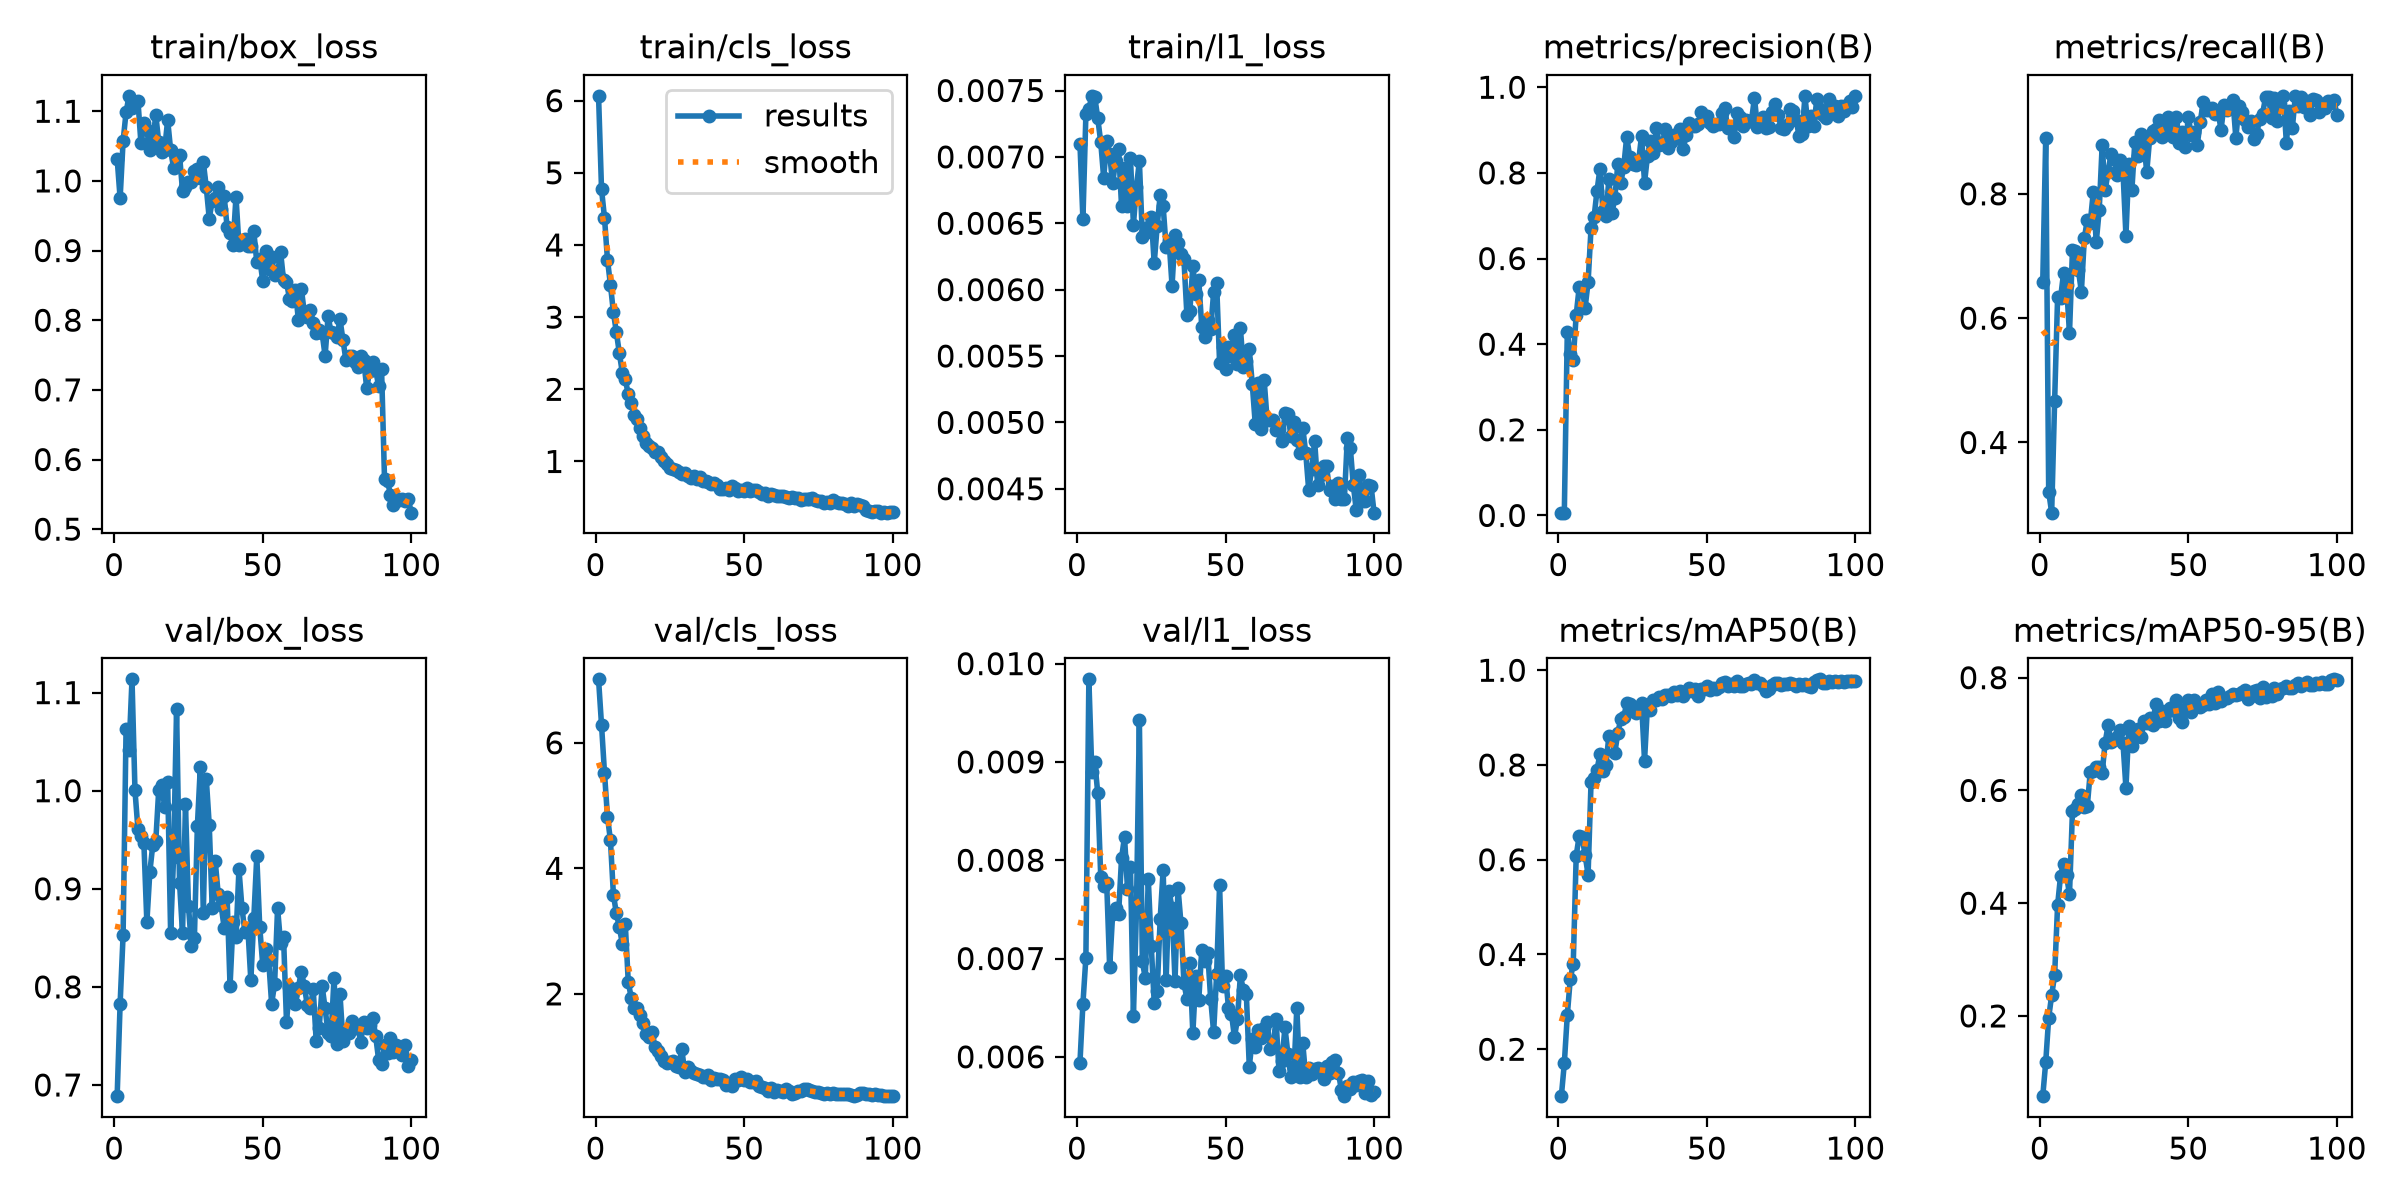

Training curves for learning rate 0.001: C:\C389_local\runs\CA1_luggage\lr_baseline\results.png


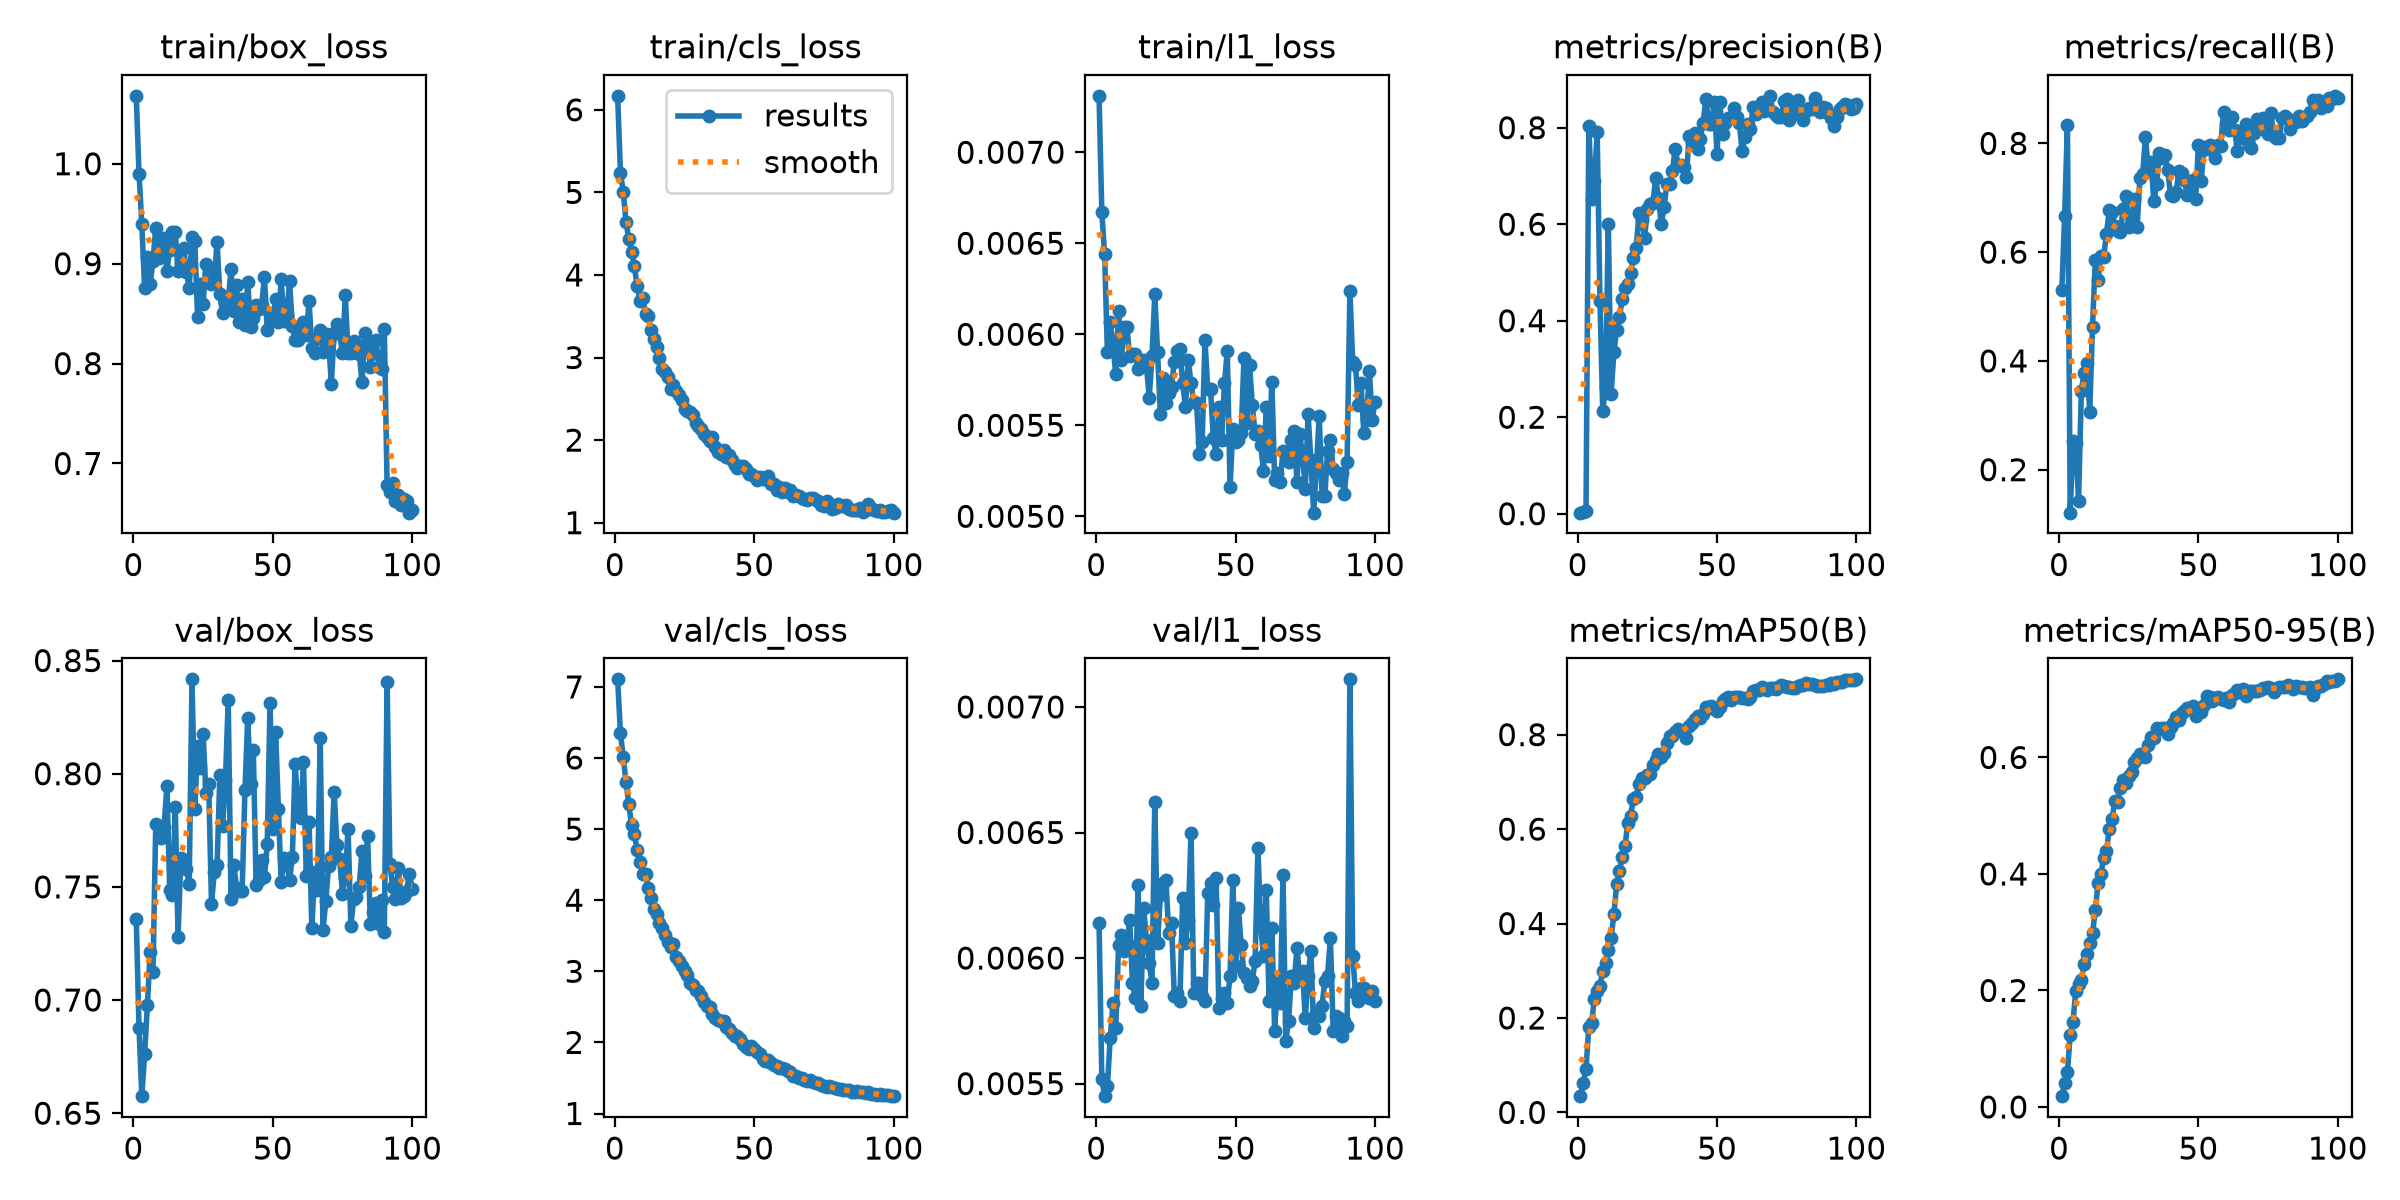

Training curves for learning rate 0.0001: C:\C389_local\runs\CA1_luggage\lr_candidate_1\results.png


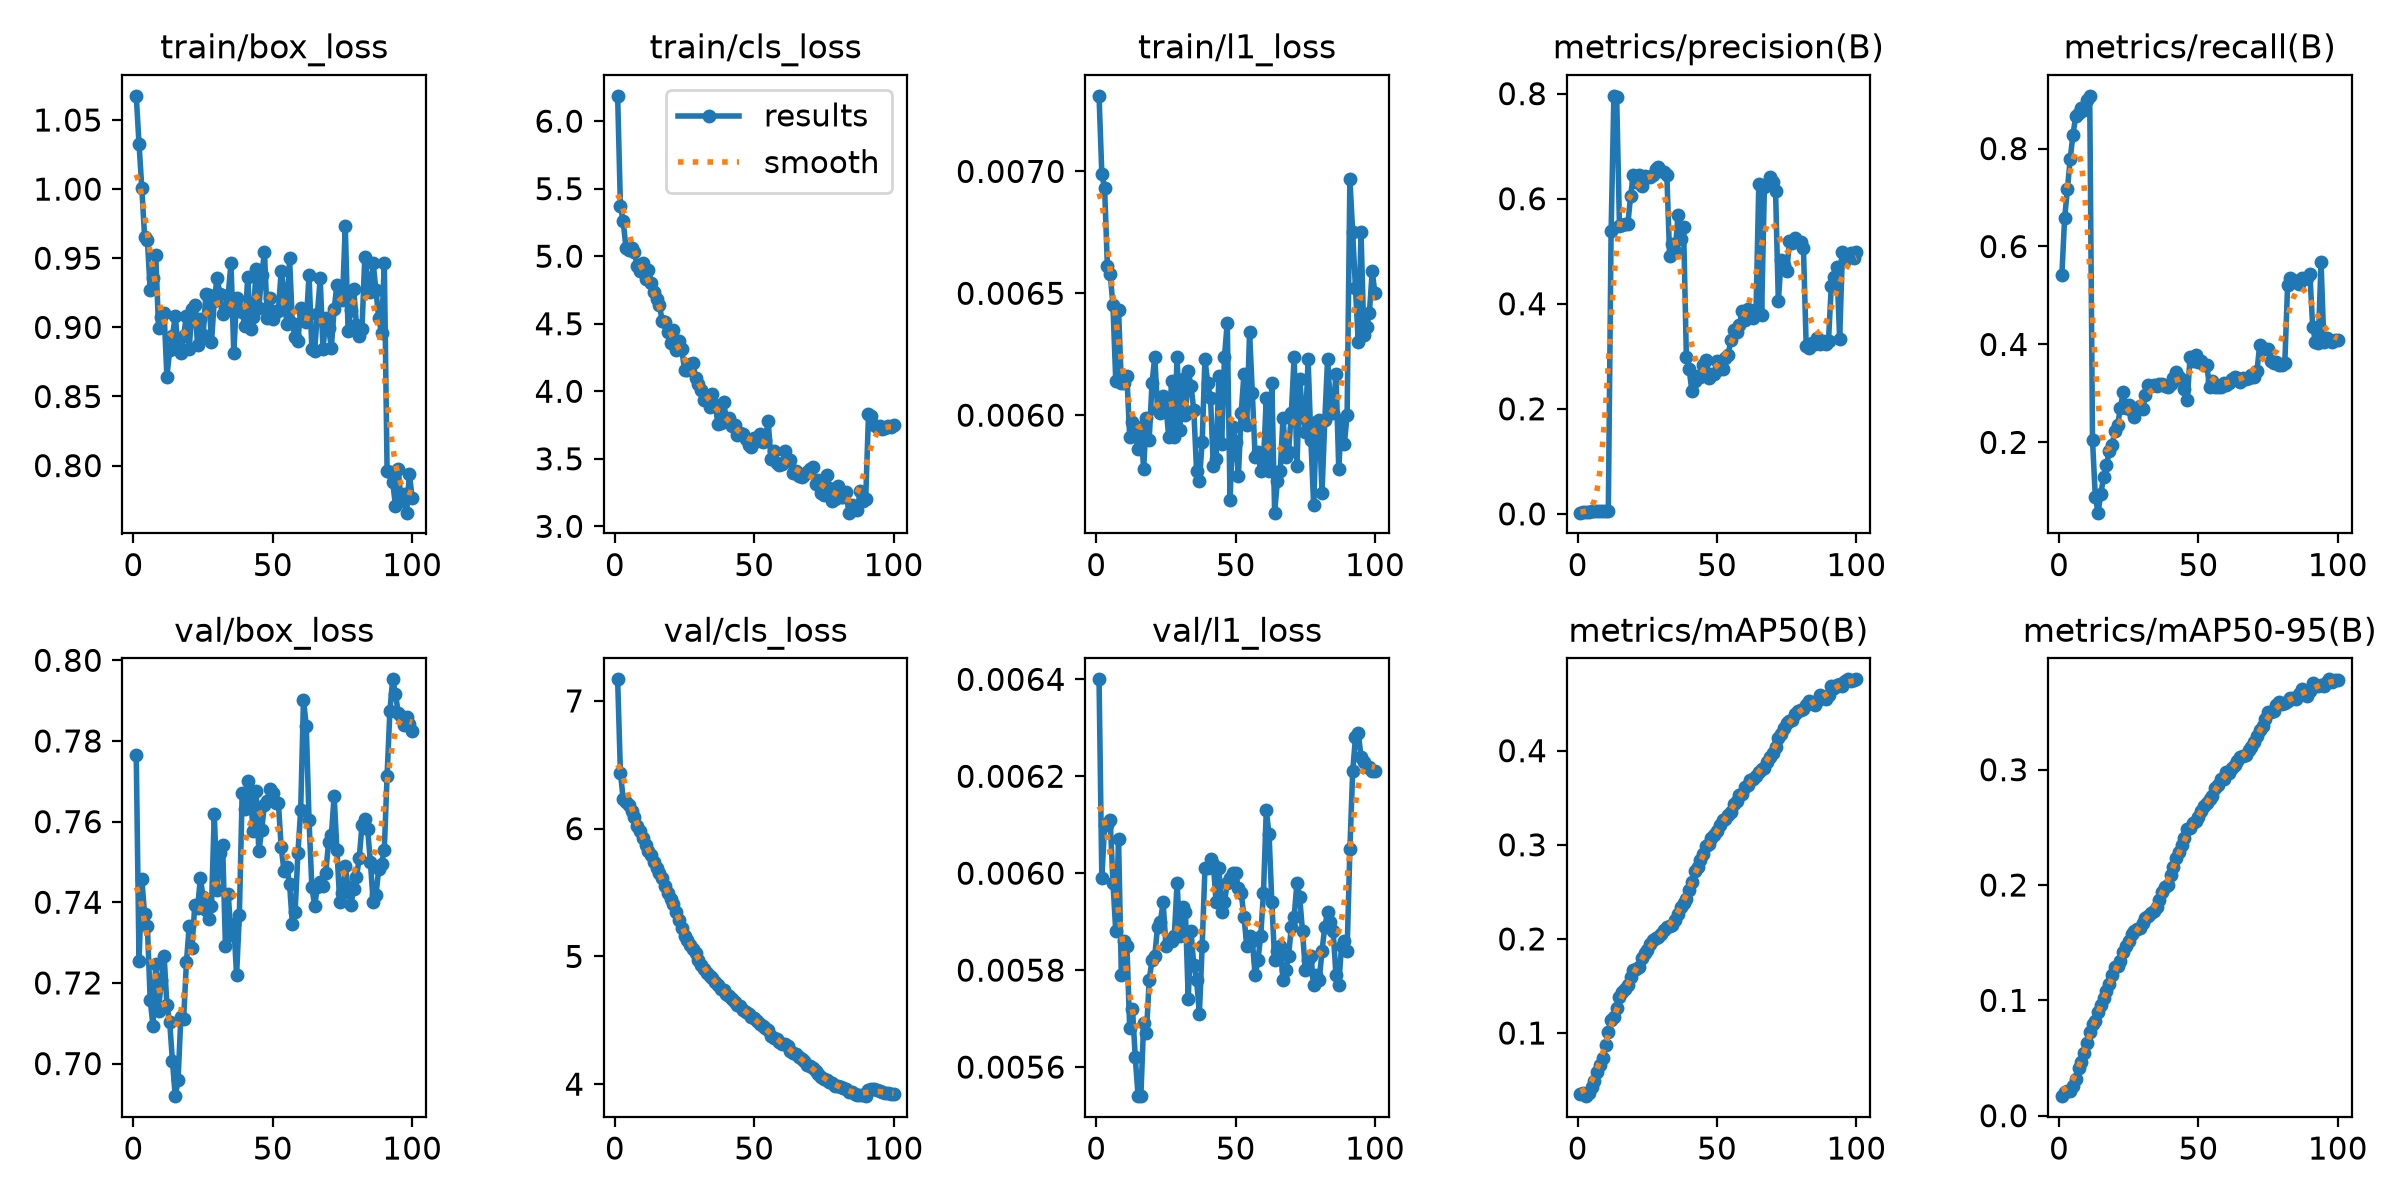

In [20]:
for row in comparison_rows:
    results_image = Path(row["run_dir"]) / "results.png"
    print(f"Training curves for learning rate {row['candidate']}: {results_image}")

    if results_image.is_file():
        display(Image(filename=str(results_image)))

In [21]:
metric_specs = [
    ("metrics/precision(B)", "Validation precision"),
    ("metrics/recall(B)", "Validation recall"),
    ("metrics/mAP50(B)", "Validation mAP50"),
    ("metrics/mAP50-95(B)", "Validation mAP50-95"),
]

figure, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for axis, (metric_column, title) in zip(axes, metric_specs):
    for row in comparison_rows:
        csv_path = Path(row["run_dir"]) / "results.csv"

        if not csv_path.is_file():
            continue

        history = clean_results_csv(csv_path)

        if metric_column in history.columns:
            axis.plot(
                range(1, len(history) + 1),
                history[metric_column],
                label=str(row["candidate"]),
            )

    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.25)
    axis.legend()

figure.suptitle("Learning-rate comparison", fontsize=14)
figure.tight_layout()

curve_output = Path(WORK_DIR) / "learning_rate_metric_curves.png"

figure.savefig(curve_output, dpi=180, bbox_inches="tight")

plt.show()

print("Saved:", curve_output)

<Figure size 1300x900 with 4 Axes>

Saved: C:\C389_local\runs\CA1_luggage\learning_rate_metric_curves.png


---

## 7B. Batch Size Tuning

Compare three batch sizes while keeping the other training
settings unchanged.

The three batch sizes are 8, 16 and 32.
Use validation mAP50 to compare the results.

In [22]:
LEARNING_RATE = 0.001 #Best Learning Rate
BATCH_SIZE = 8
RUN_NAME = "batch_8"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_rat

In [23]:
BATCH_SIZE = 16
RUN_NAME = "batch_16_baseline"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ra

In [24]:
BATCH_SIZE = 32
RUN_NAME = "batch_32"

model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    lr0=LEARNING_RATE,
    optimizer="SGD",
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    workers=WORKERS,
    plots=True,
    verbose=True,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_luggage\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ra

### 7B.1 Batch Size Comparison

Compare the validation performance of the three batch sizes.

In [25]:
BATCH_EXPERIMENTS = [
    {"batch": 8, "name": "batch_8"},
    {"batch": 16, "name": "batch_16_baseline"},
    {"batch": 32, "name": "batch_32"},
]

PROJECT_DIR = Path(WORK_DIR)

comparison_rows = []

for experiment in BATCH_EXPERIMENTS:
    batch_size = experiment["batch"]
    run_name = experiment["name"]
    run_dir = PROJECT_DIR / run_name
    csv_path = run_dir / "results.csv"

    if not csv_path.exists():
        print(f"Skipping {run_name}: results.csv not found.")
        continue

    results = clean_results_csv(csv_path)

    precision_col = find_column(results.columns, ["metrics/precision"])
    recall_col = find_column(results.columns, ["metrics/recall"])
    map50_col = find_column(results.columns, ["metrics/map50(b)"])
    map5095_col = find_column(results.columns, ["metrics/map50-95"])

    if map50_col is None:
        raise KeyError(
            f"Could not find the mAP50 column in {csv_path}."
        )

    best_index = results[map50_col].astype(float).idxmax()
    best_row = results.loc[best_index]

    comparison_rows.append({
        "Run": run_name,
        "Batch size": batch_size,
        "Precision": float(best_row[precision_col]) if precision_col else None,
        "Recall": float(best_row[recall_col]) if recall_col else None,
        "mAP50": float(best_row[map50_col]),
        "mAP50-95": float(best_row[map5095_col]) if map5095_col else None,
        "Best epoch": int(best_row["epoch"]) + 1 if "epoch" in results.columns else int(best_index) + 1,
        "Best checkpoint": str(run_dir / "weights" / "best.pt"),
        "candidate": batch_size,
        "run_dir": str(run_dir),
    })

comparison_df = pd.DataFrame(comparison_rows)

if comparison_df.empty:
    raise RuntimeError("No completed batch-size results were found.")

comparison_df = comparison_df.sort_values(
    by=["mAP50", "Precision", "Recall", "mAP50-95"],
    ascending=[False, False, False, False],
).reset_index(drop=True)

display(comparison_df)

comparison_df.to_csv(
    Path(WORK_DIR) / "batch_size_comparison.csv",
    index=False,
)

best_run = comparison_df.iloc[0]

print("\nSelected batch size:", int(best_run["Batch size"]))
print("Selected run:", best_run["Run"])
print("Validation mAP50:", best_run["mAP50"])

,Run,Batch size,Precision,Recall,mAP50,mAP50-95,Best epoch,Best checkpoint,candidate,run_dir
0,batch_32,32,0.83296,0.90631,0.92916,0.73625,98,C:\C389_local\runs\CA1_luggage\batch_32\weight...,32,C:\C389_local\runs\CA1_luggage\batch_32
1,batch_8,8,0.87878,0.82105,0.91798,0.73348,85,C:\C389_local\runs\CA1_luggage\batch_8\weights...,8,C:\C389_local\runs\CA1_luggage\batch_8
2,batch_16_baseline,16,0.84834,0.88353,0.91713,0.73411,101,C:\C389_local\runs\CA1_luggage\batch_16_baseli...,16,C:\C389_local\runs\CA1_luggage\batch_16_baseline



Selected batch size: 32
Selected run: batch_32
Validation mAP50: 0.92916


In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Batch size"].astype(str),
    comparison_df["mAP50"],
)

plt.xlabel("Batch size")
plt.ylabel("Best validation mAP50")
plt.title("YOLO26n Batch-Size Comparison")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

<Figure size 800x500 with 1 Axes>

Training curves for batch size 8: C:\C389_local\runs\CA1_luggage\batch_8\results.png


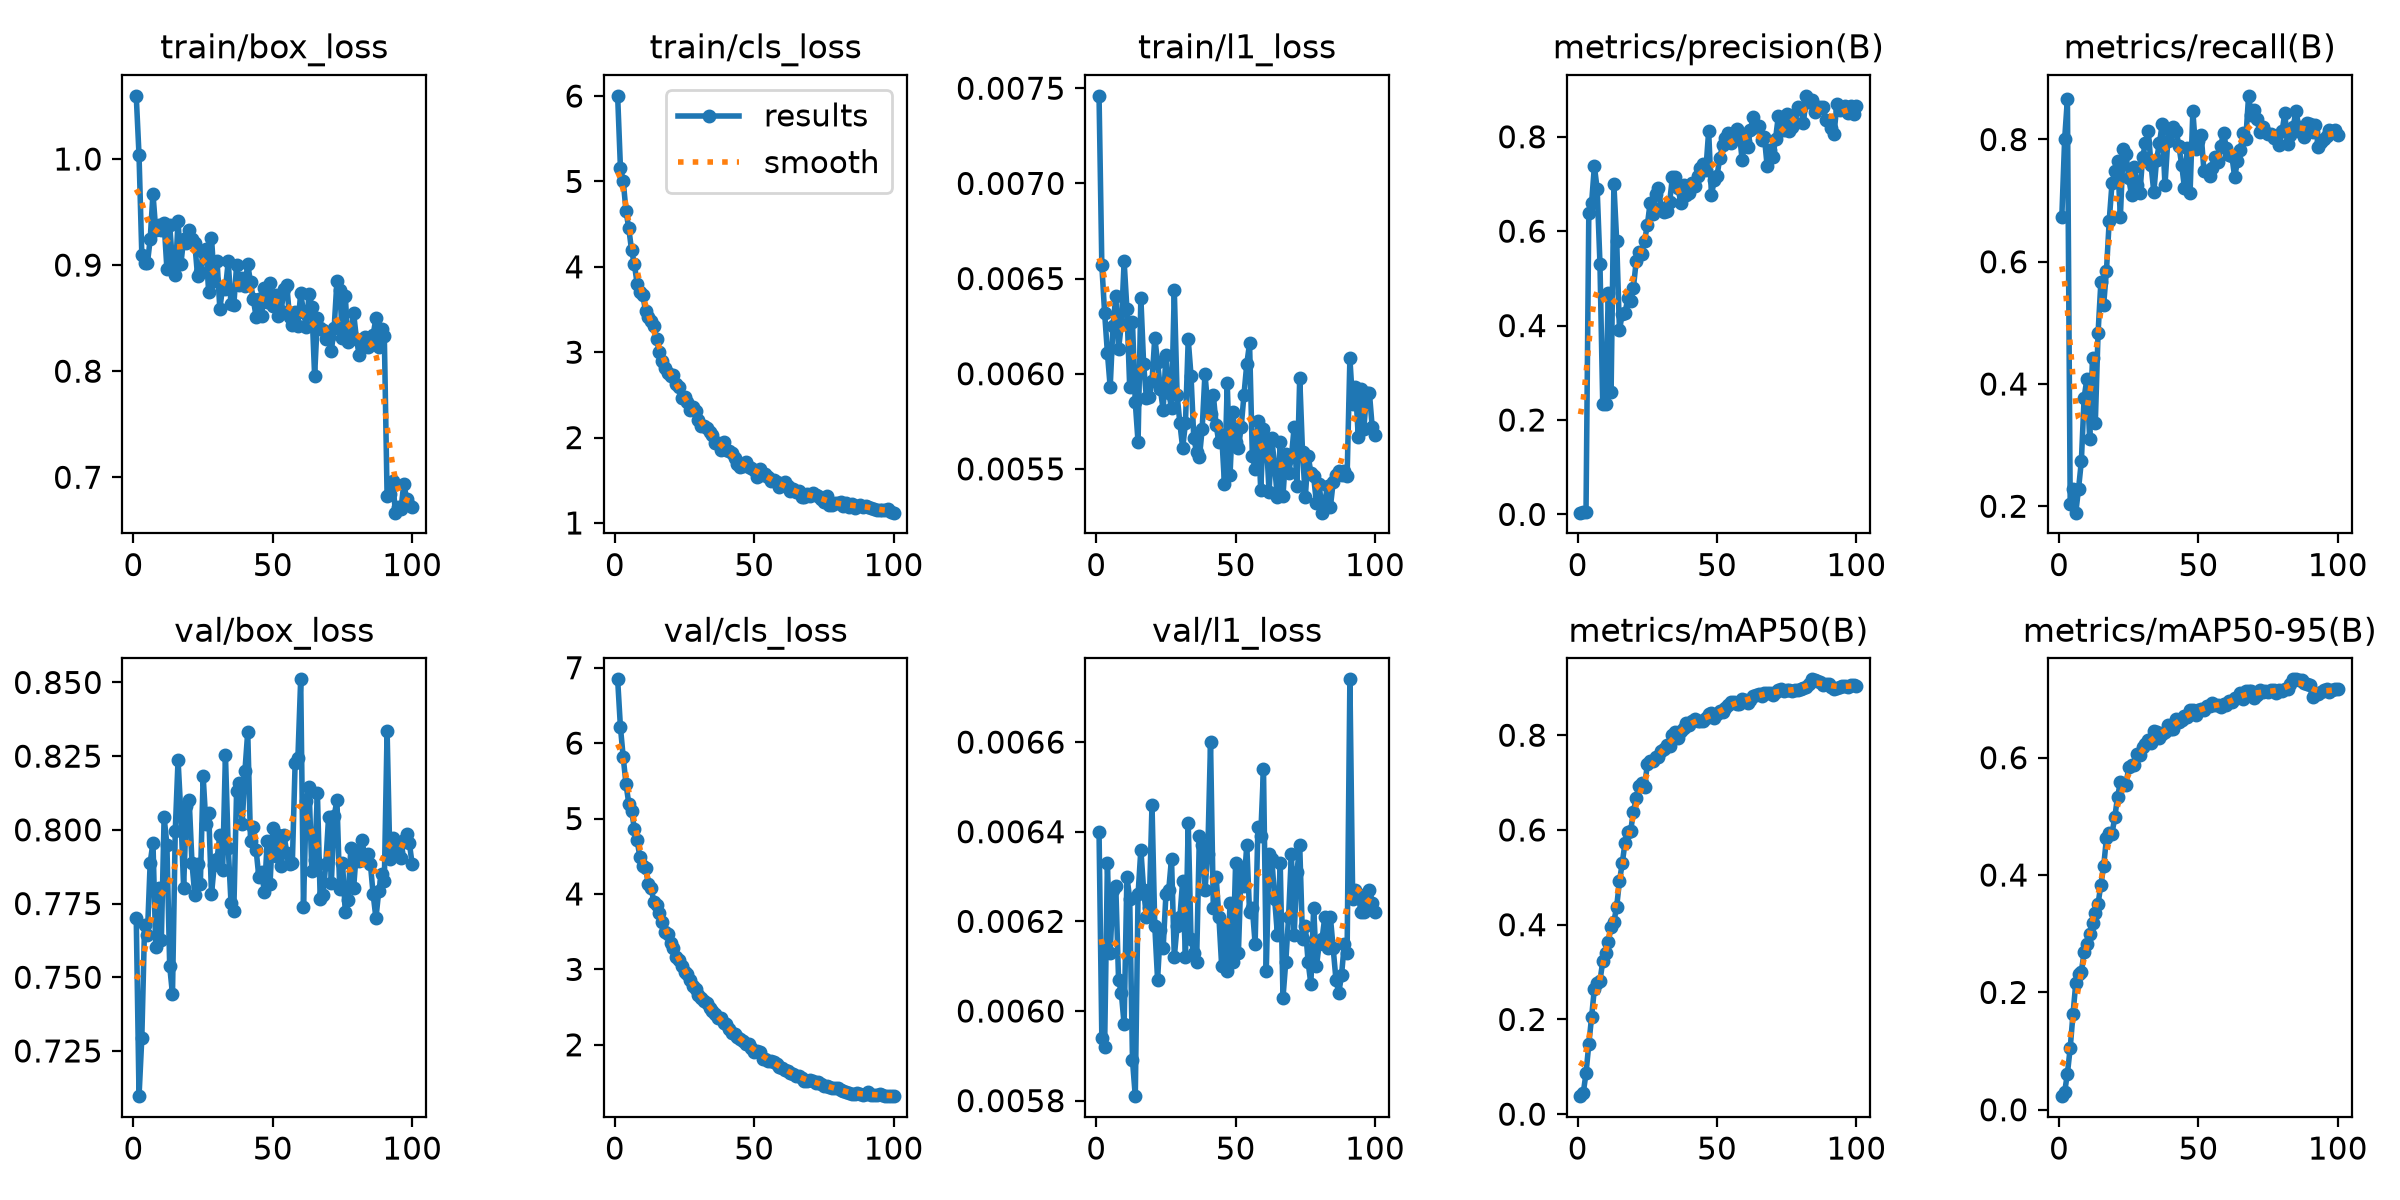

Training curves for batch size 16: C:\C389_local\runs\CA1_luggage\batch_16_baseline\results.png


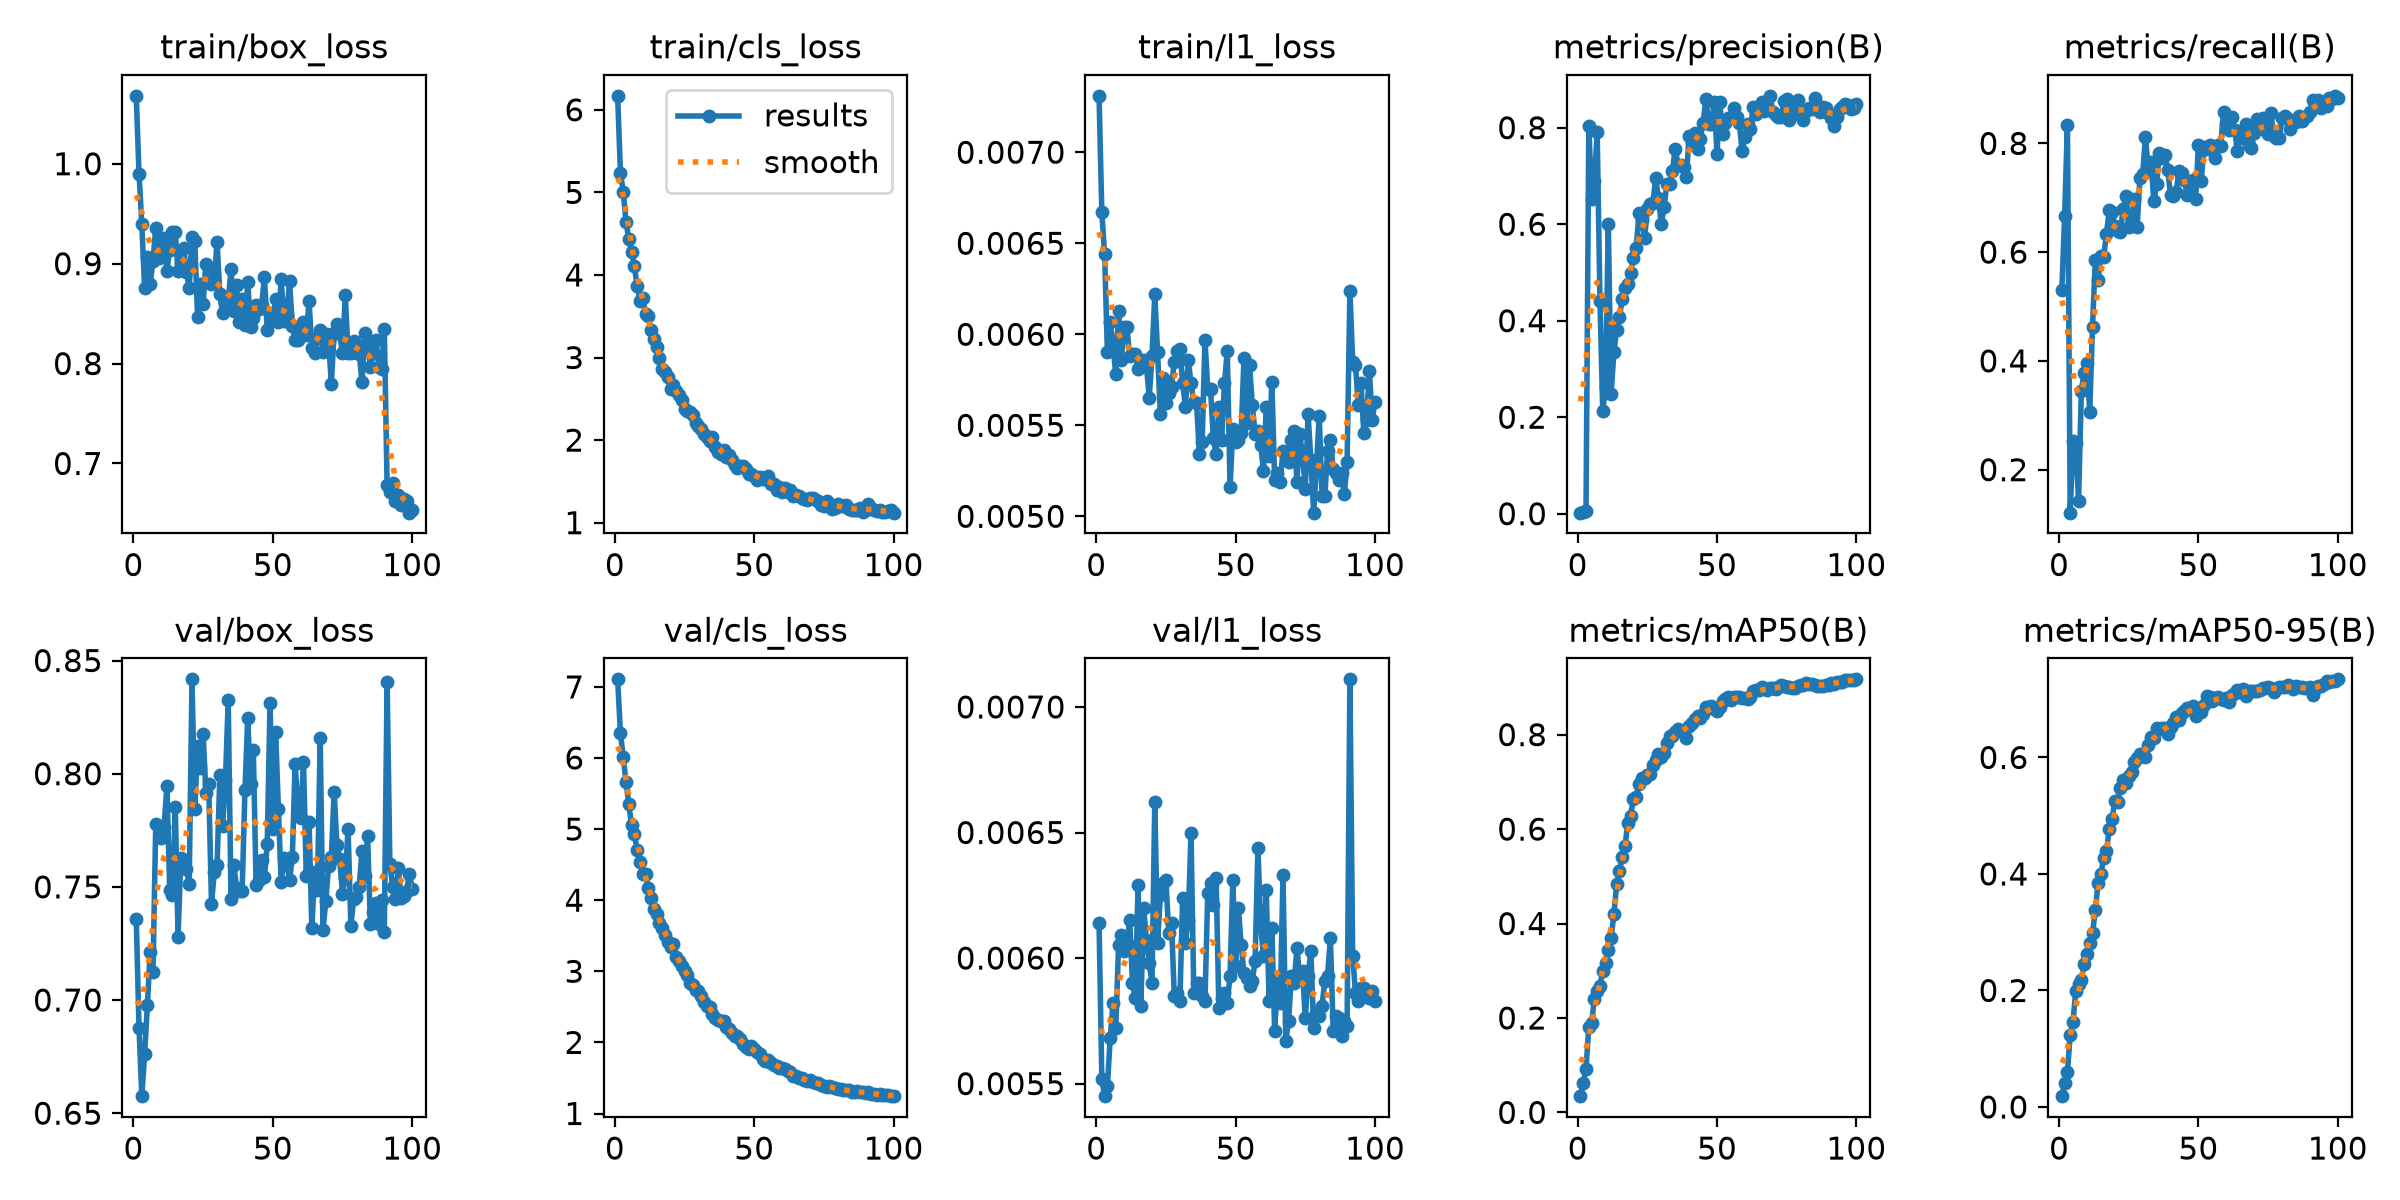

Training curves for batch size 32: C:\C389_local\runs\CA1_luggage\batch_32\results.png


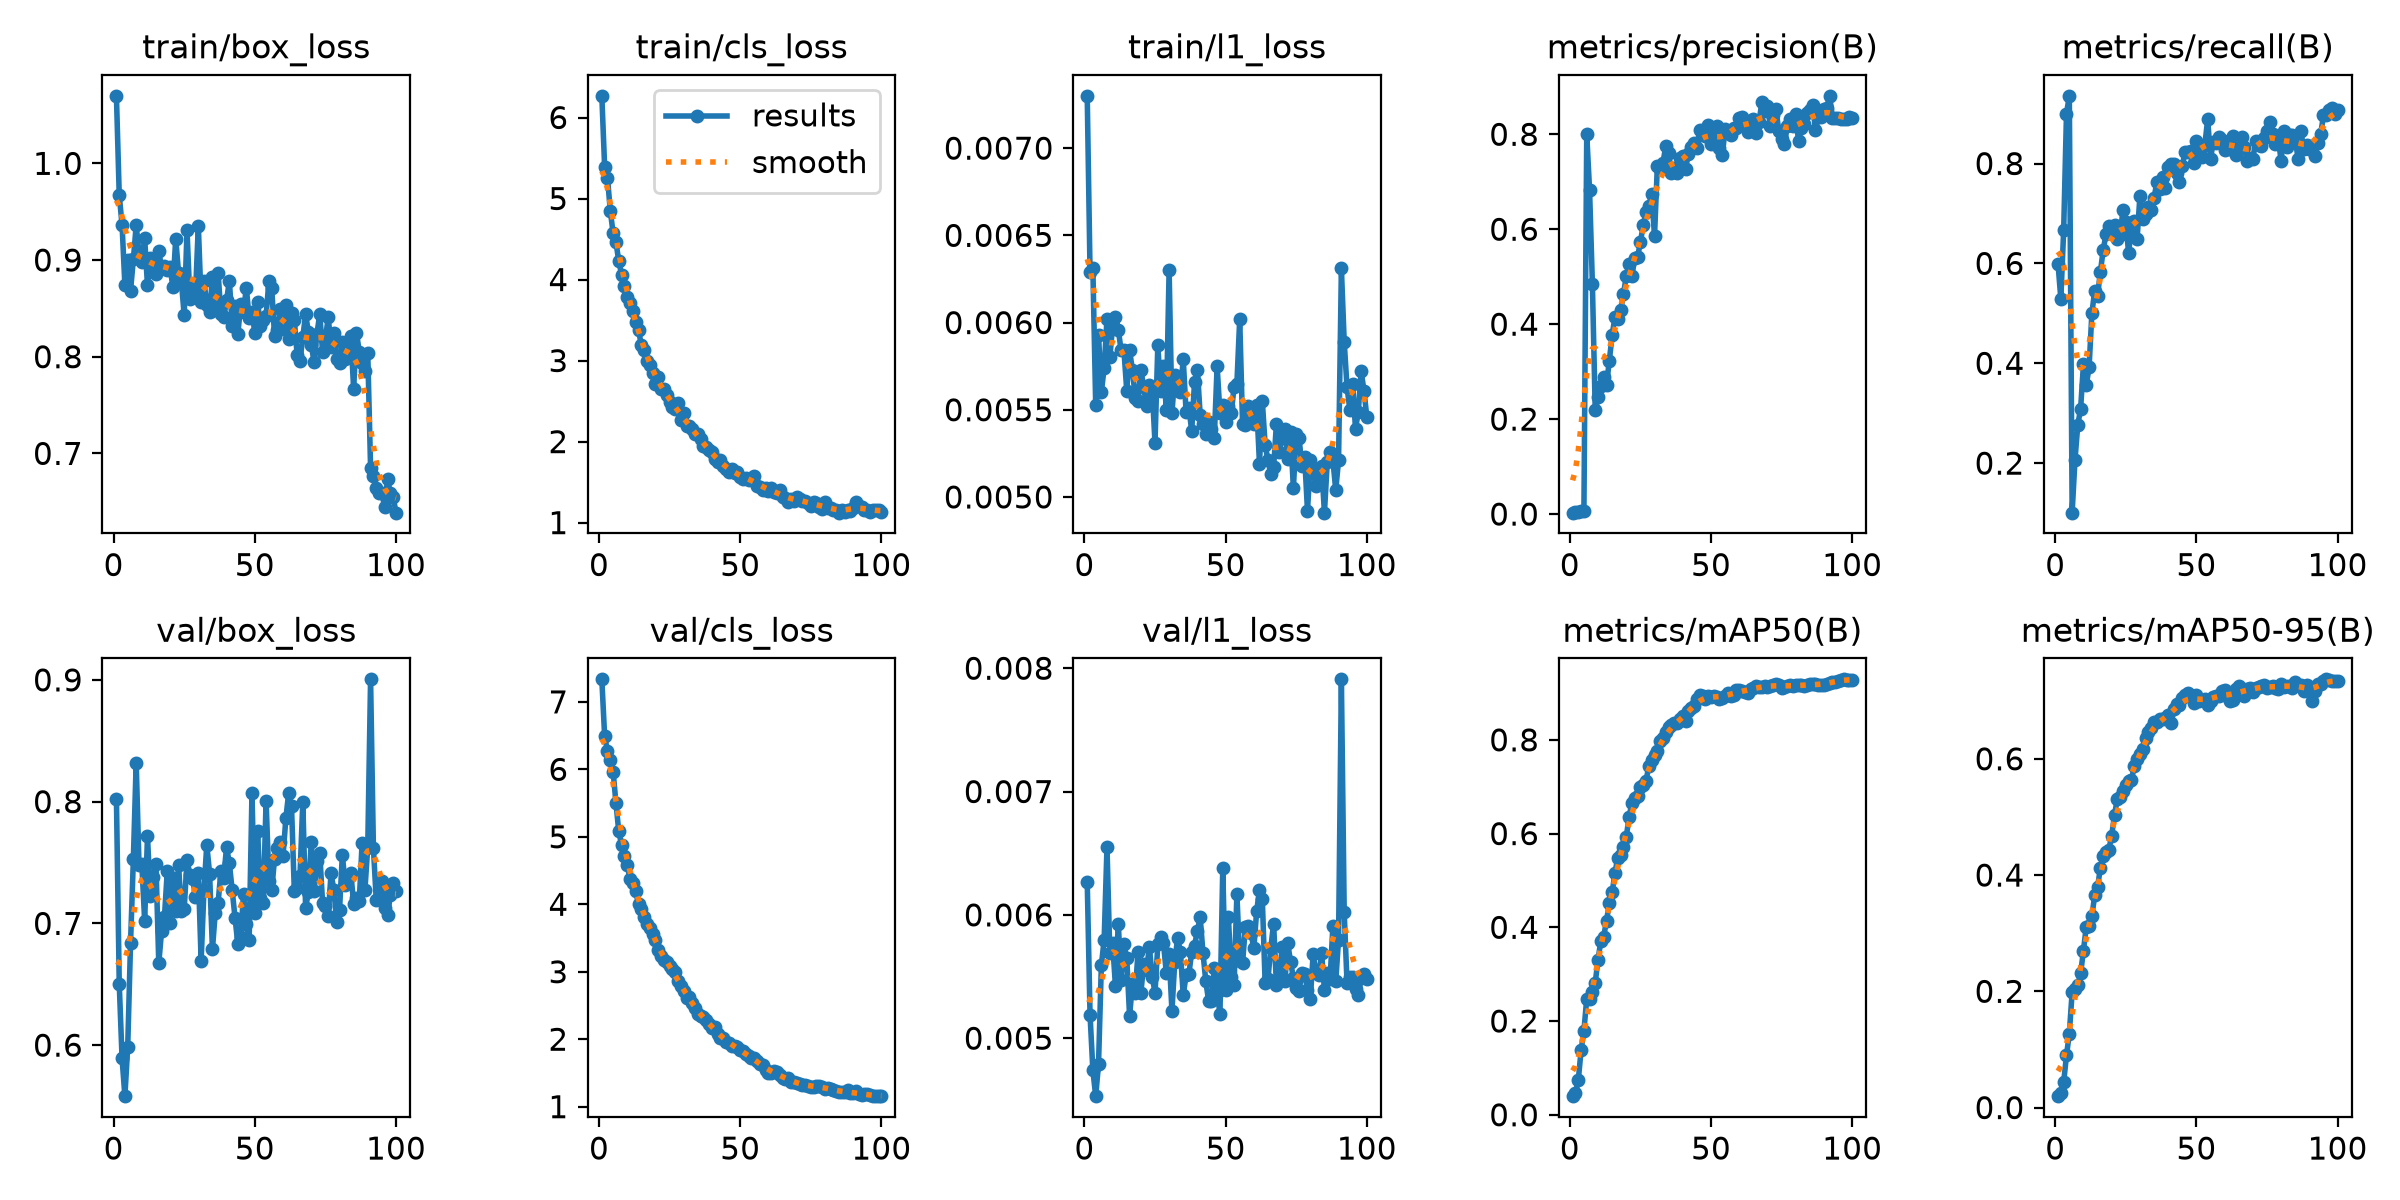

In [27]:
for row in comparison_rows:
    results_image = Path(row["run_dir"]) / "results.png"
    print(f"Training curves for batch size {row['candidate']}: {results_image}")

    if results_image.is_file():
        display(Image(filename=str(results_image)))

In [28]:
metric_specs = [
    ("metrics/precision(B)", "Validation precision"),
    ("metrics/recall(B)", "Validation recall"),
    ("metrics/mAP50(B)", "Validation mAP50"),
    ("metrics/mAP50-95(B)", "Validation mAP50-95"),
]

figure, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for axis, (metric_column, title) in zip(axes, metric_specs):
    for row in comparison_rows:
        csv_path = Path(row["run_dir"]) / "results.csv"

        if not csv_path.is_file():
            continue

        history = clean_results_csv(csv_path)

        if metric_column in history.columns:
            axis.plot(
                range(1, len(history) + 1),
                history[metric_column],
                label=str(row["candidate"]),
            )

    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.25)
    axis.legend()

figure.suptitle("Batch-size comparison", fontsize=14)
figure.tight_layout()

curve_output = Path(WORK_DIR) / "batch_size_metric_curves.png"

figure.savefig(curve_output, dpi=180, bbox_inches="tight")

plt.show()

print("Saved:", curve_output)

<Figure size 1300x900 with 4 Axes>

Saved: C:\C389_local\runs\CA1_luggage\batch_size_metric_curves.png


In [29]:
selected_checkpoint = Path(best_run["Best checkpoint"])

if not selected_checkpoint.exists():
    raise FileNotFoundError(
        f"Selected checkpoint not found: {selected_checkpoint}"
    )

RUN_NAME = str(best_run["Run"])
RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)

BEST_WEIGHTS = str(selected_checkpoint)
BATCH_SIZE = int(best_run["Batch size"])

print("Selected batch size:", BATCH_SIZE)
print("Selected run:", RUN_NAME)
print("Selected weights:", BEST_WEIGHTS)
print("Validation mAP50:", best_run["mAP50"])

Selected batch size: 32
Selected run: batch_32
Selected weights: C:\C389_local\runs\CA1_luggage\batch_32\weights\best.pt
Validation mAP50: 0.92916


---

## 8. Reading the result

Per class, never only the mean. `luggage_left` against `luggage_right` is the row that
matters, then the confusion between them.

In [30]:
trained = YOLO(BEST_WEIGHTS)
EVAL_SPLIT = "test" if INSTANCE_COUNTS["test"]["luggage_left"] + INSTANCE_COUNTS["test"]["luggage_right"] else "val"
EVAL_FOLDER = "test" if EVAL_SPLIT == "test" else "valid"
metrics = trained.val(data=DATA_YAML, split=EVAL_SPLIT, verbose=False, workers=WORKERS)
print("scored on:", EVAL_FOLDER)

PER_CLASS = {}
for index, class_id in enumerate(metrics.ap_class_index):
    PER_CLASS[CLASS_NAMES[int(class_id)]] = {
        "precision": float(metrics.box.p[index]),
        "recall": float(metrics.box.r[index]),
        "ap50": float(metrics.box.ap50[index]),
        "ap50_95": float(metrics.box.ap[index]),
    }

print("%-14s %9s %7s %8s %9s %9s" % ("class", "precision", "recall", "mAP@.5", "mAP@.5:.95", "instances"))
for name in CLASS_NAMES:
    if name in PER_CLASS:
        row = PER_CLASS[name]
        total = sum(INSTANCE_COUNTS[s][name] for s in ("train", "valid", "test"))
        print("%-14s %9.3f %7.3f %8.3f %9.3f %9d"
              % (name, row["precision"], row["recall"], row["ap50"], row["ap50_95"], total))

luggage_scores = [PER_CLASS[n]["ap50"] for n in LUGGAGE_CLASSES if n in PER_CLASS]
if len(luggage_scores) == 2:
    gap = max(luggage_scores) - min(luggage_scores)
    print("")
    print("gap between luggage_left and luggage_right, mAP@.5: %.3f" % gap)
    if gap >= 0.10:
        print("Wide gap: check the class balance and the annotations before any setting.")
    else:
        print("The two directions were learned about equally well.")

Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 8.21.7 MB/s, size: 41.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning C:\C389_local\runs\CA1_luggage\dataset_by_scene\test\labels... 96 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 796.8it/s 0.1s0.1s
val: New cache created: C:\C389_local\runs\CA1_luggage\dataset_by_scene\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.4it/s 1.4s0.3s
                   all         96        174      0.854      0.827      0.917      0.737
Speed: 0.9ms preprocess, 5.0ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to C:\C389_local\notebooks\ru

results.png


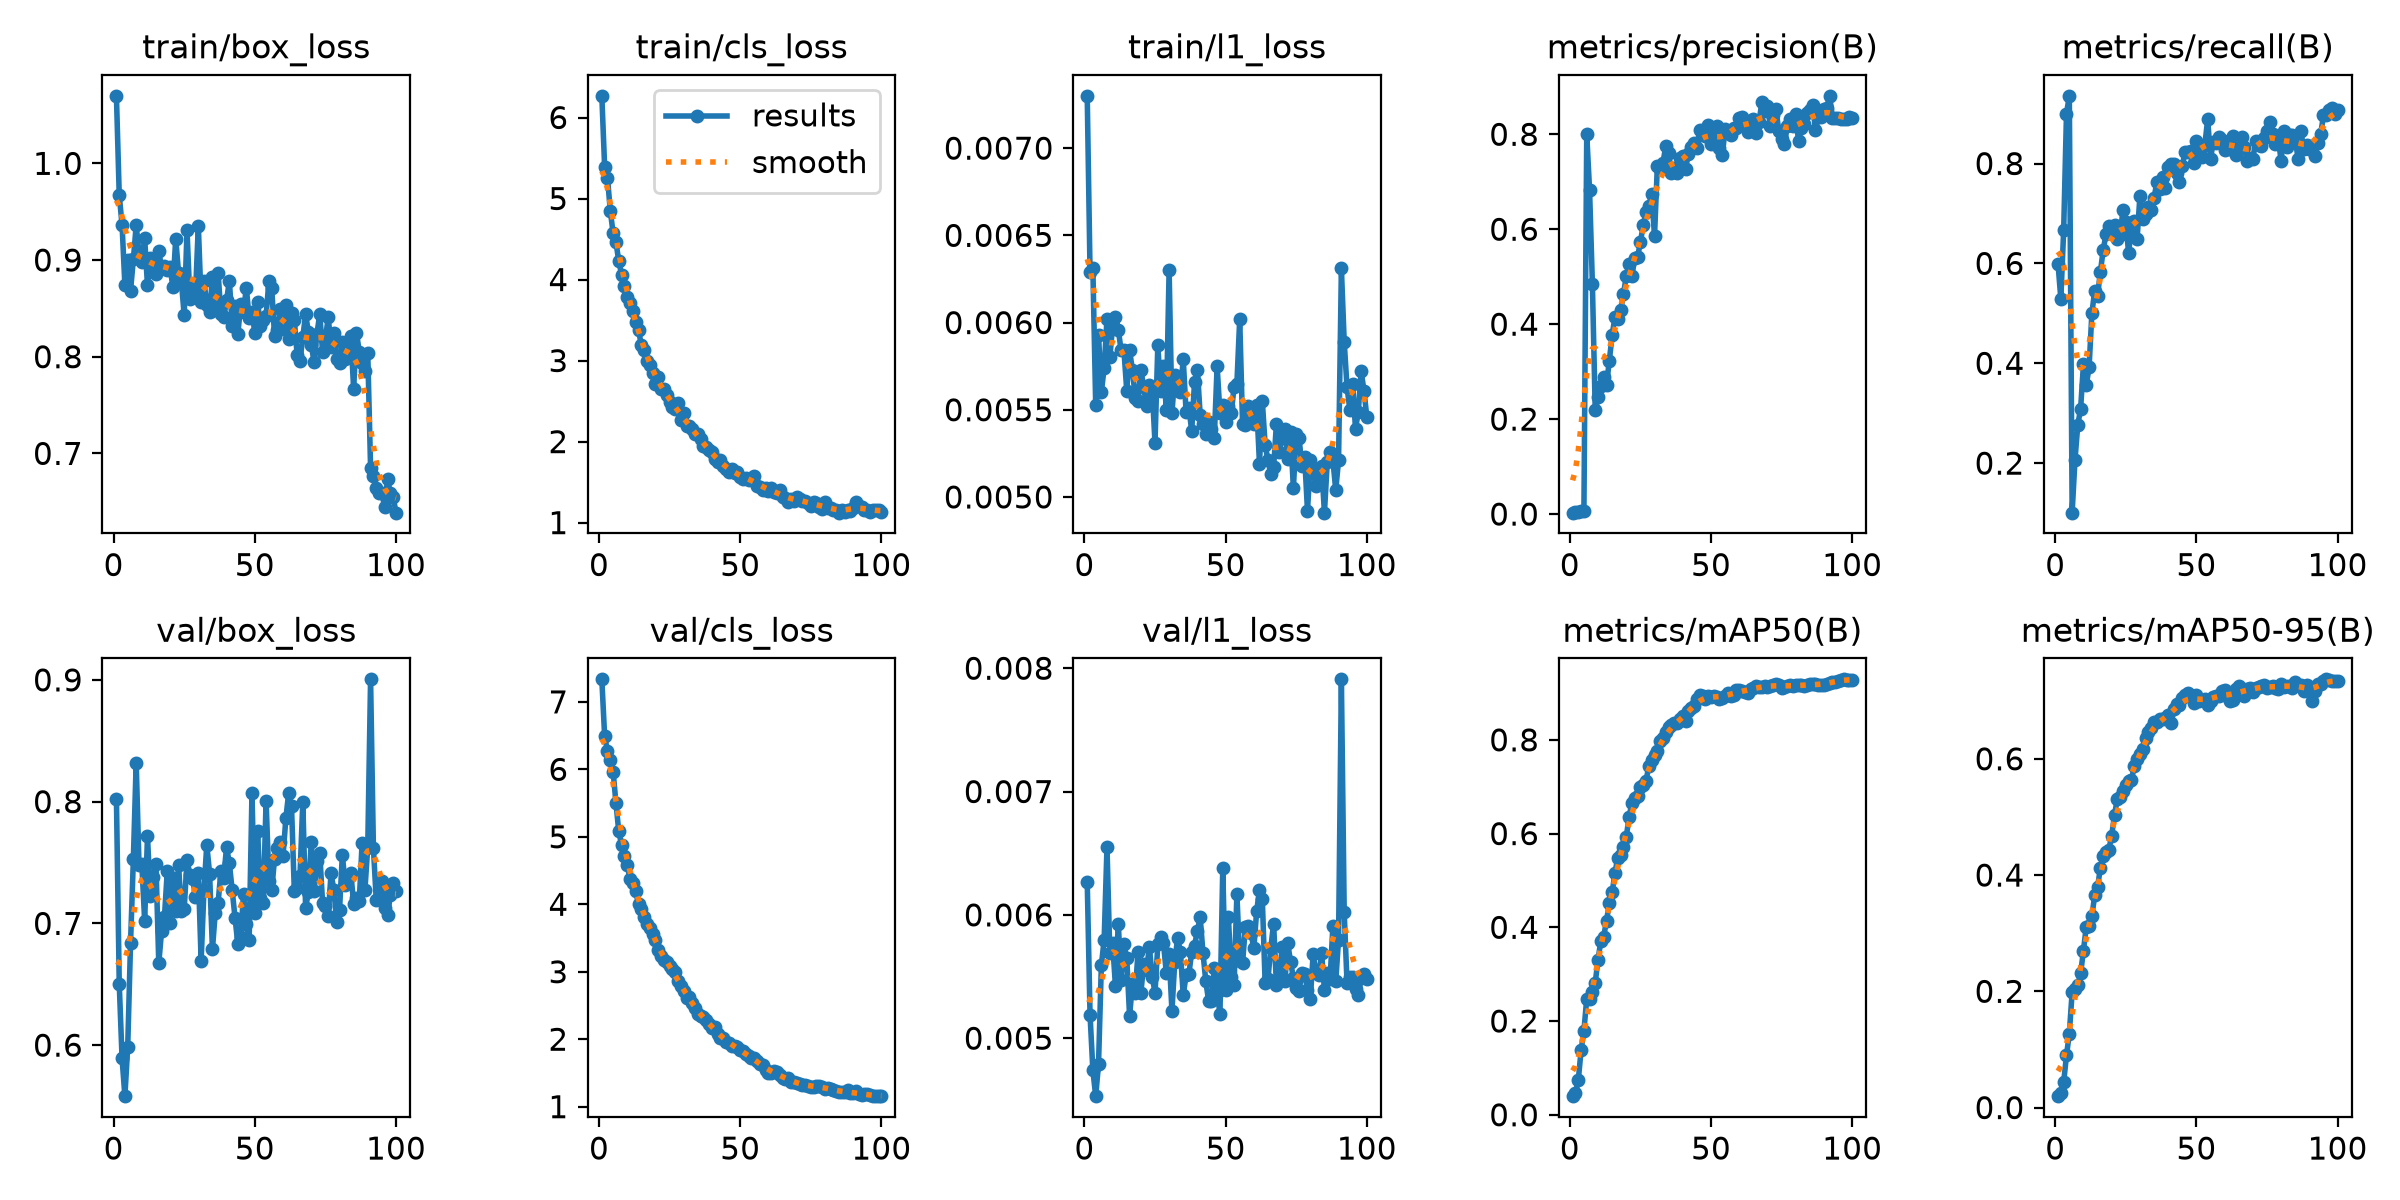

BoxPR_curve.png


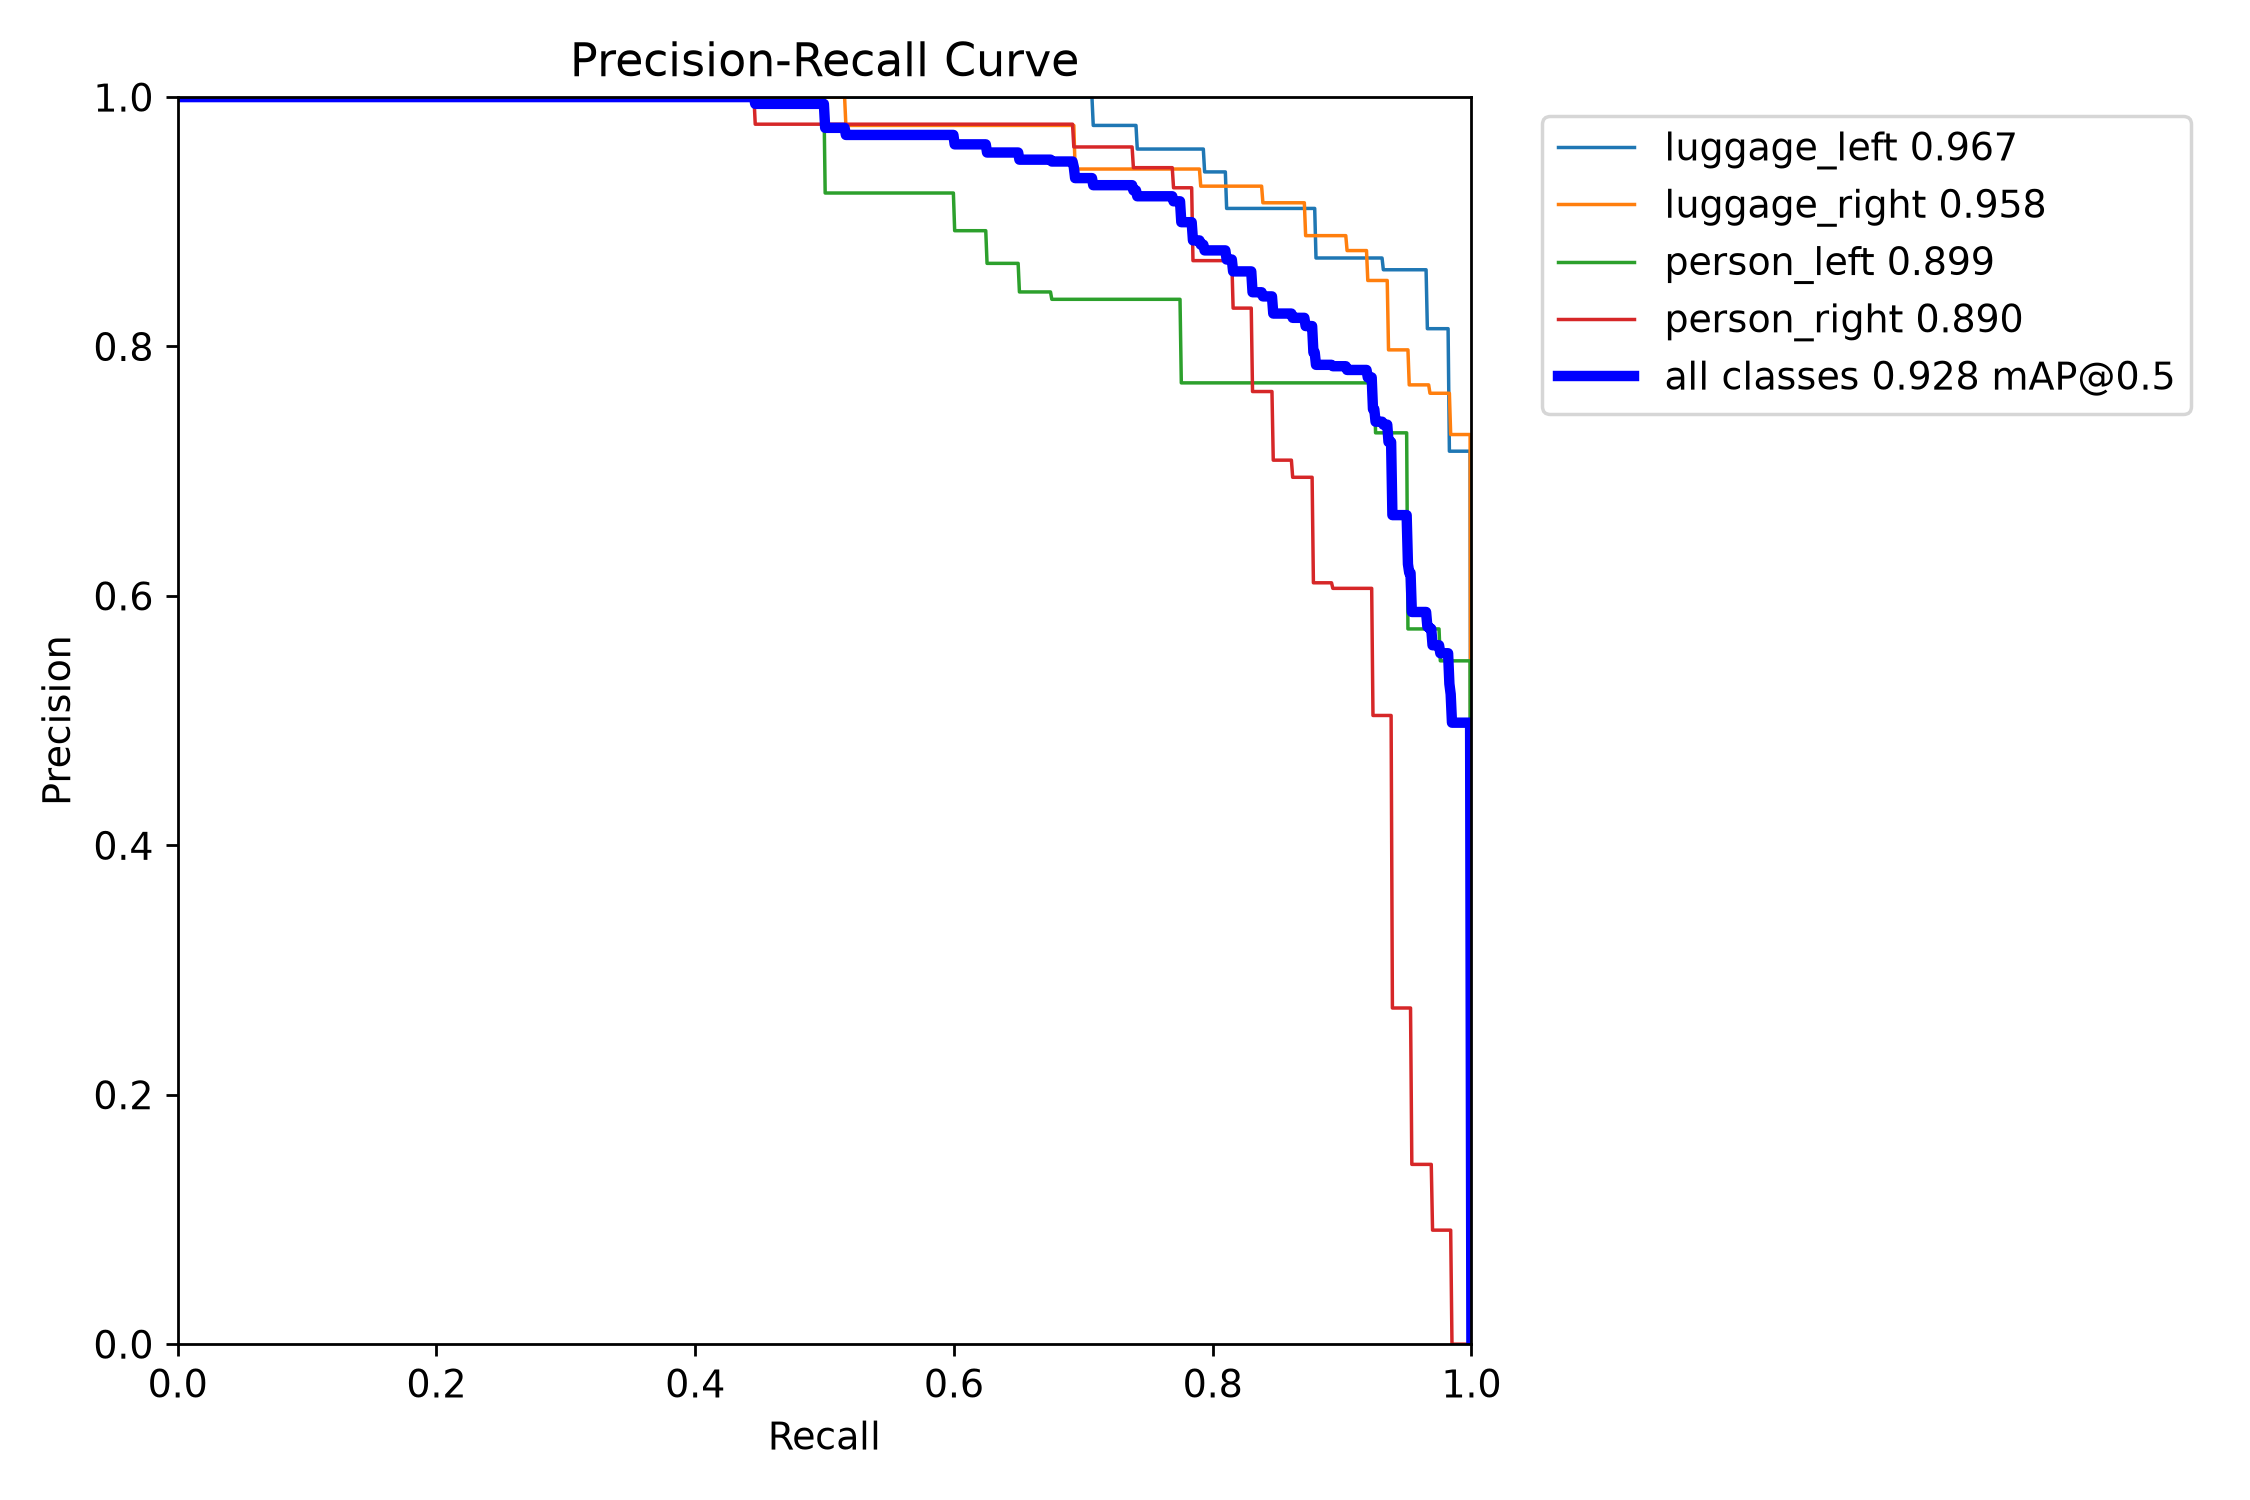

confusion_matrix.png


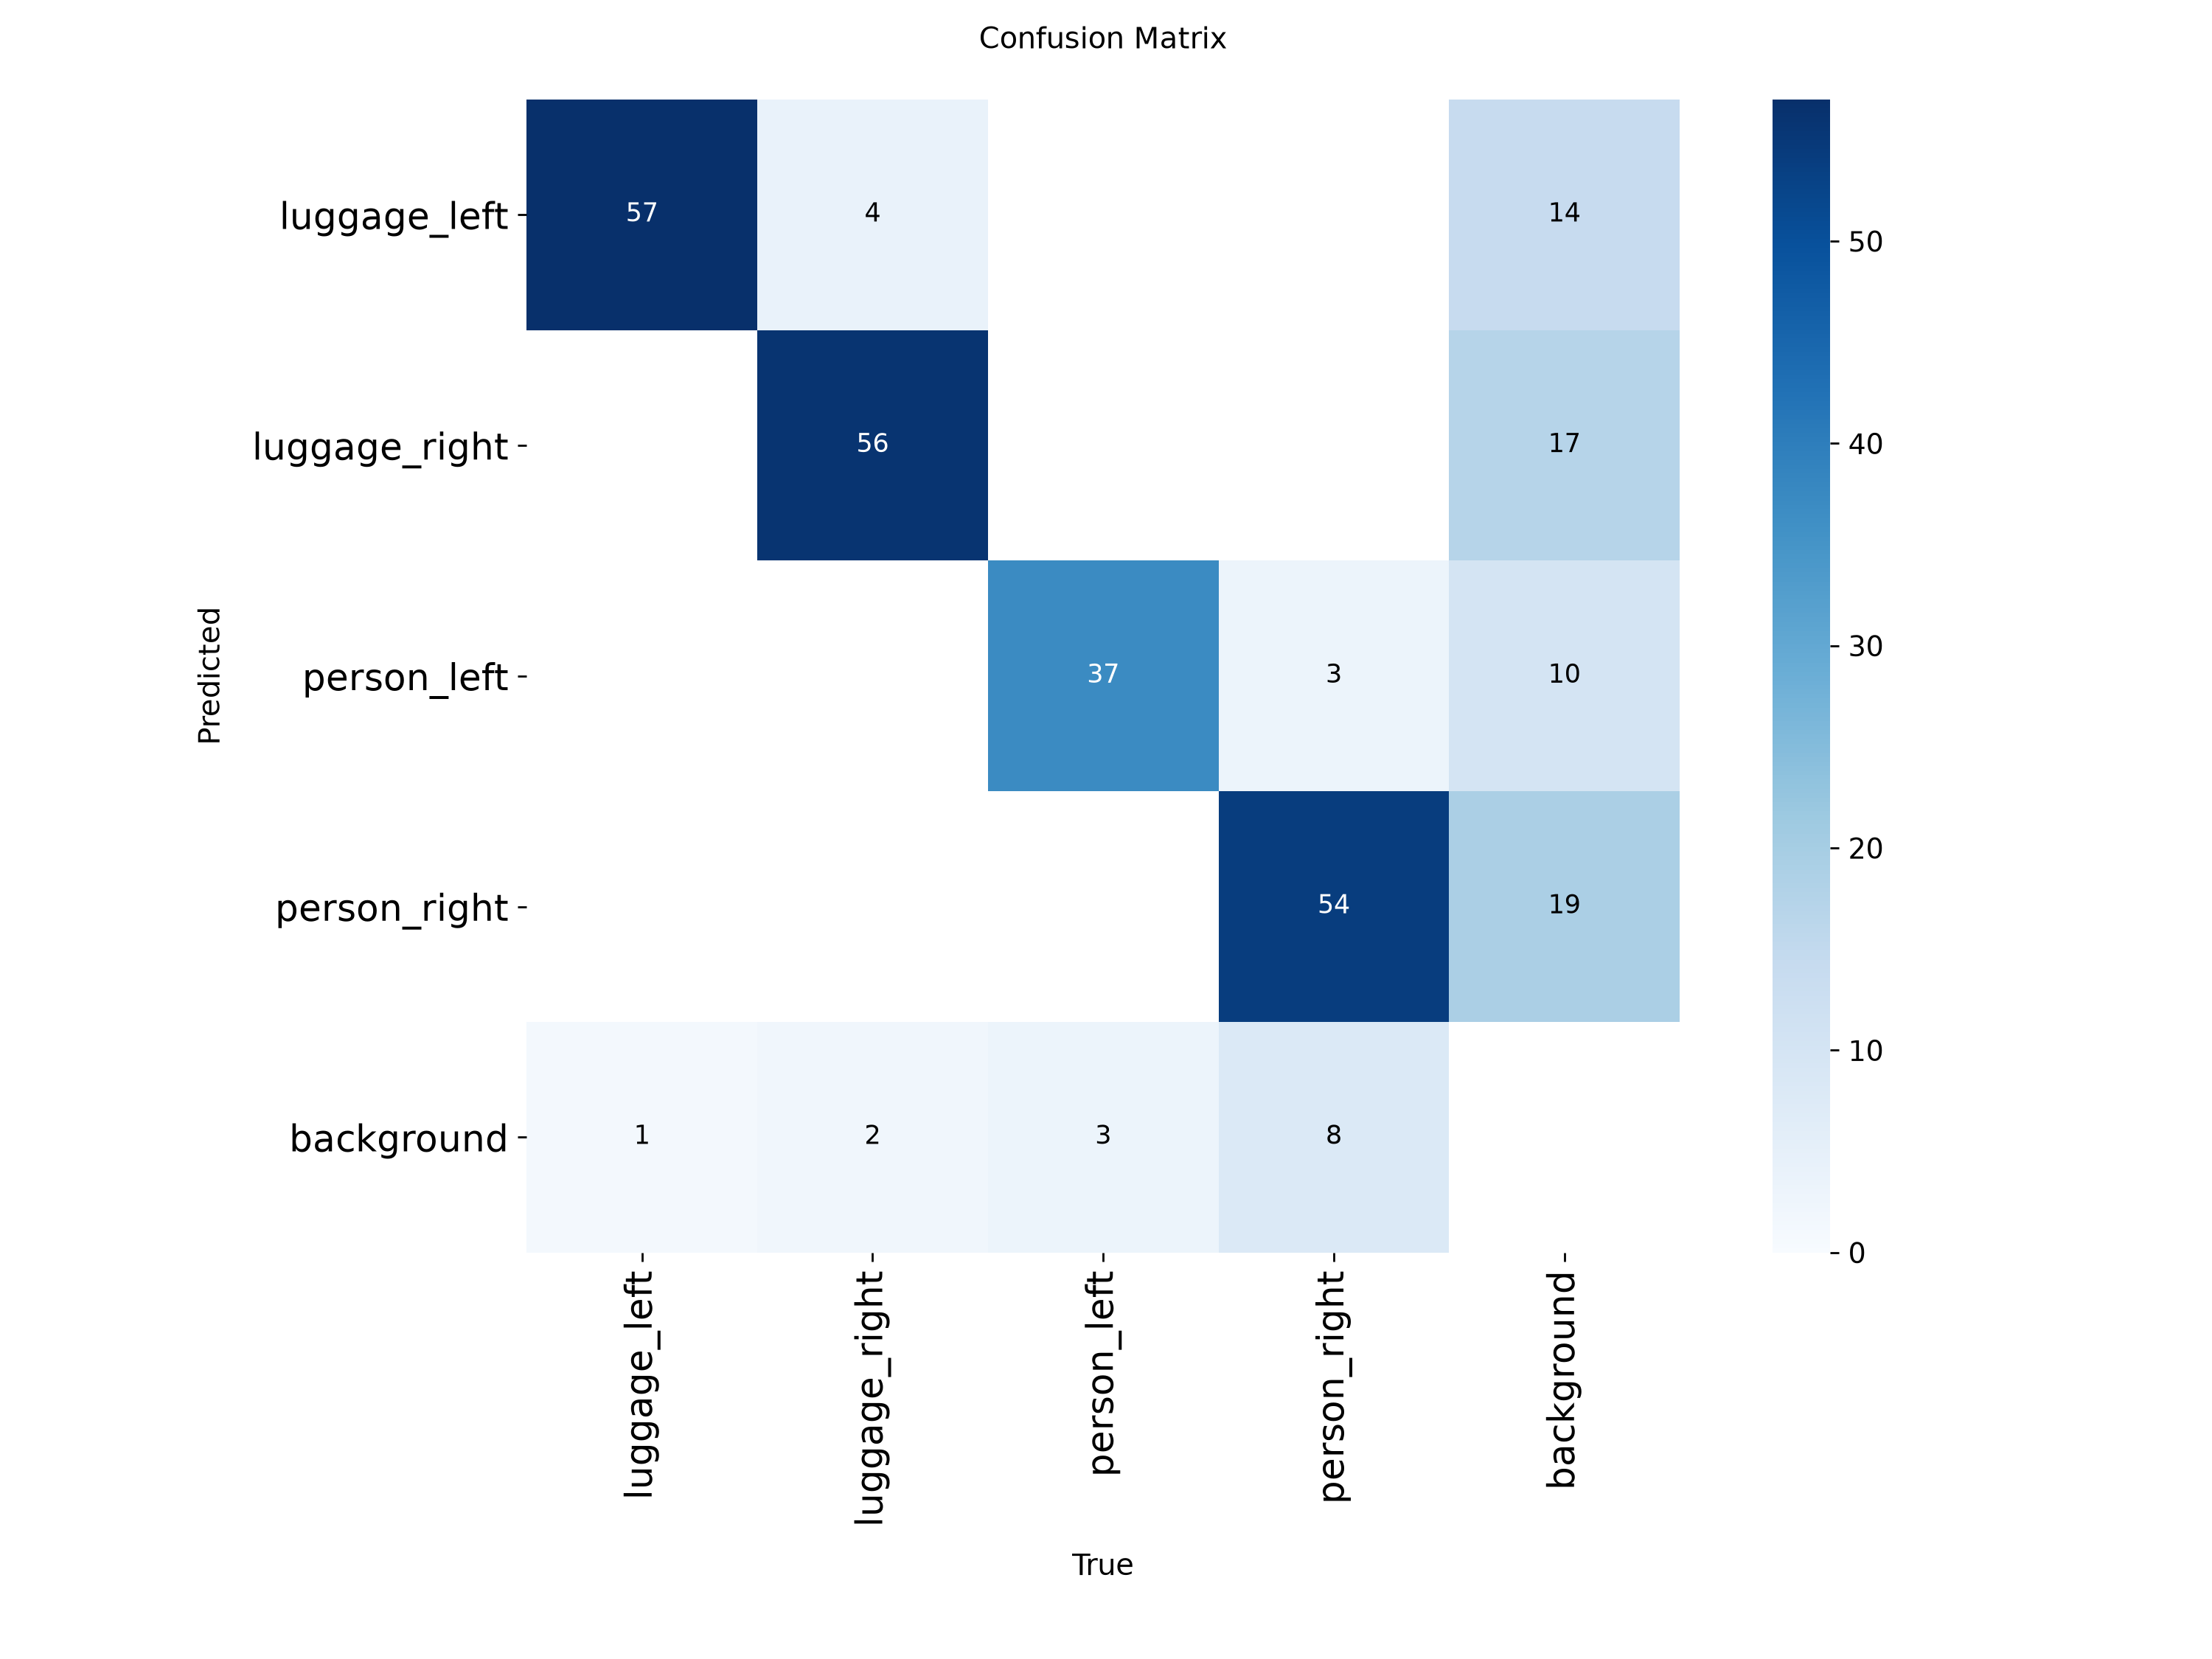

In [31]:
from IPython.display import Image as ShowImage, display

for name in ("results.png", "BoxPR_curve.png", "confusion_matrix.png"):
    path = os.path.join(RUN_DIR, name)
    if os.path.exists(path):
        print(name)
        display(ShowImage(filename=path, width=760))

In [32]:
# Left read as right, and the reverse. This is the failure mode of the project, and it is
# different from missing the bag altogether. Rows are the annotated class, columns what
# the model predicted. "background" is a miss (row) or an invented box (column).
try:
    matrix = metrics.confusion_matrix.matrix          # indexed [predicted][annotated]
    labels = CLASS_NAMES + ["background"]
    print("%-14s" % "annotated" + "".join("%15s" % l[:14] for l in labels))
    for true_id, true_name in enumerate(labels):
        print("%-14s" % true_name[:14]
              + "".join("%15d" % int(matrix[pred_id][true_id]) for pred_id in range(len(labels))))
except Exception as error:
    print("Could not read the confusion matrix:", error)

annotated        luggage_left  luggage_right    person_left   person_right     background
luggage_left               41              2              0              0             13
luggage_right               0             48              0              1              5
person_left                 0              0             20              0              2
person_right                0              0              0             35              7
background                  4              8              5             10              0


---

## 9. Does it work on every angle

The dataset has 6 camera positions. One number for the whole test set can hide an angle
that fails completely. For each test image the cell compares the annotated count of each
luggage class with the predicted count, then groups by the angle in the file name.

In [33]:
CONFIDENCE_THRESHOLD = 0.40
ANGLE_RE = re.compile(r"_A(\d)_")


def label_counts(label_path, class_names):
    counts = {name: 0 for name in class_names}
    if os.path.exists(label_path):
        with open(label_path, encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    counts[class_names[int(line.split()[0])]] += 1
    return counts


per_angle = defaultdict(lambda: {"images": 0, "exact": 0, "direction_flips": 0})
image_dir = os.path.join(DATASET_DIR, EVAL_FOLDER, "images")
for name in sorted(os.listdir(image_dir)):
    if not name.lower().endswith(IMAGE_EXTS):
        continue
    match = ANGLE_RE.search(name)
    angle = "A" + match.group(1) if match else "other"
    truth = label_counts(os.path.join(DATASET_DIR, EVAL_FOLDER, "labels",
                                      os.path.splitext(name)[0] + ".txt"), CLASS_NAMES)
    result = trained.predict(os.path.join(image_dir, name), conf=CONFIDENCE_THRESHOLD,
                             verbose=False)[0]
    predicted = {n: 0 for n in CLASS_NAMES}
    for class_id in result.boxes.cls.tolist():
        predicted[CLASS_NAMES[int(class_id)]] += 1
    row = per_angle[angle]
    row["images"] += 1
    row["exact"] += all(truth[n] == predicted[n] for n in LUGGAGE_CLASSES)
    row["direction_flips"] += (truth["luggage_left"] > predicted["luggage_left"]
                               and predicted["luggage_right"] > truth["luggage_right"]) or \
                              (truth["luggage_right"] > predicted["luggage_right"]
                               and predicted["luggage_left"] > truth["luggage_left"])

print("%-6s %7s %22s %17s" % ("angle", "images", "luggage counts exact", "direction flipped"))
for angle in sorted(per_angle):
    row = per_angle[angle]
    print("%-6s %7d %15d (%3.0f%%) %17d"
          % (angle, row["images"], row["exact"], 100 * row["exact"] / row["images"],
             row["direction_flips"]))

angle   images   luggage counts exact direction flipped
A1          15               7 ( 47%)                 1
A2           5               0 (  0%)                 0
A3          10               9 ( 90%)                 0
A4           5               5 (100%)                 0
A5          16               4 ( 25%)                 0
A6           4               4 (100%)                 0
other       41              41 (100%)                 0


1000041281_jpg.rf.2a202c75ac9c3c3a88b0fd0f2338a65a.jpg


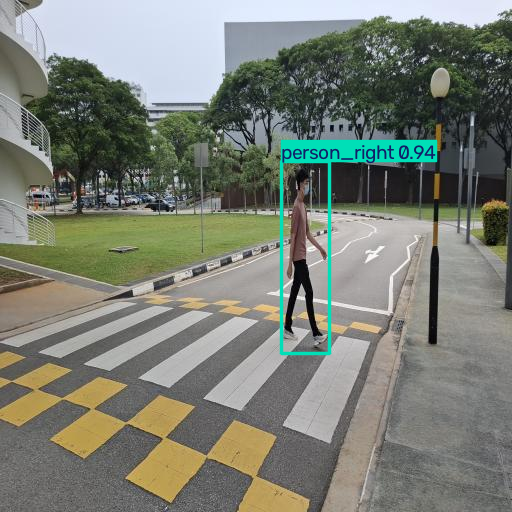

1000041315_jpg.rf.a8fffbd20f20ca683abf68df1ad5f5a7.jpg


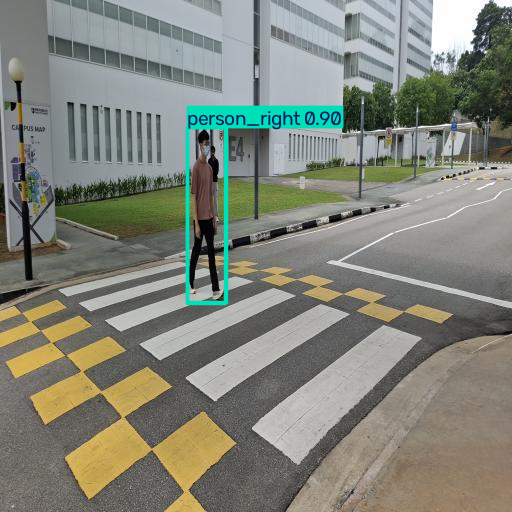

1000041323_jpg.rf.1c16ab04df1baf4e93743323d72bdff1.jpg


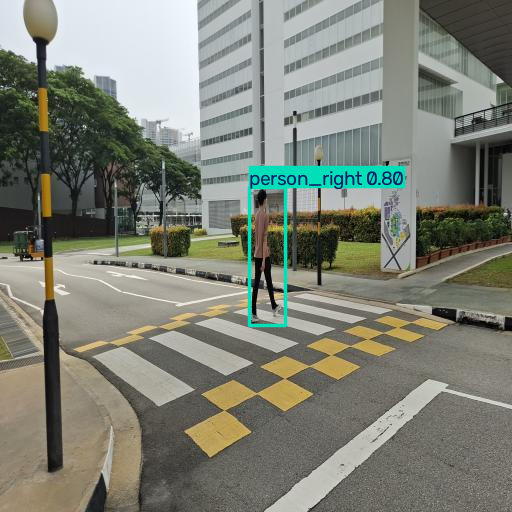

1000065250_jpg.rf.f26c5dd747dcc548d469fcebbe0ef46c.jpg


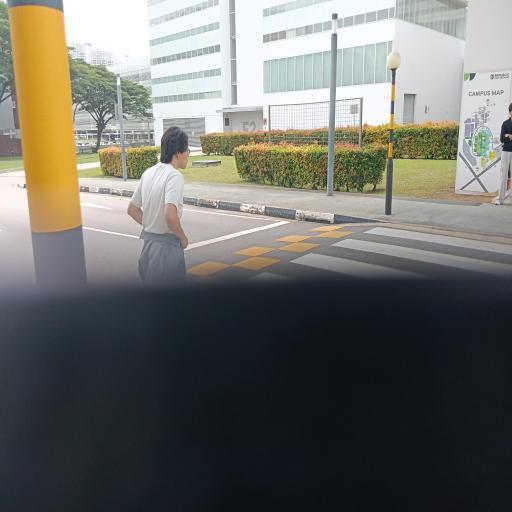

In [34]:
# Look at what the model did on a few test images, boxes and classes drawn on.
from PIL import Image as PILImage

shown = 0
for name in sorted(os.listdir(image_dir)):
    if name.lower().endswith(IMAGE_EXTS) and shown < 4:
        result = trained.predict(os.path.join(image_dir, name), conf=CONFIDENCE_THRESHOLD,
                                 verbose=False)[0]
        print(name)
        display(PILImage.fromarray(result.plot()[:, :, ::-1]))
        shown += 1

---

## 10. Keep the result

In [35]:
ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts", "CA1_luggage")
os.makedirs(ARTIFACT_DIR, exist_ok=True)
shutil.copy(BEST_WEIGHTS, os.path.join(ARTIFACT_DIR, "best.pt"))

with open(os.path.join(ARTIFACT_DIR, "metrics.json"), "w", encoding="utf-8") as handle:
    json.dump({
        "classes": CLASS_NAMES,
        "per_class": PER_CLASS,
        "instances": INSTANCE_COUNTS,
        "resplit_by_scene": RESPLIT_BY_SCENE,
        "scored_on": EVAL_FOLDER,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "config": {"model_variant": MODEL_VARIANT, "epochs": EPOCHS,
                   "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
                   "fliplr": FLIP_LEFT_RIGHT},
    }, handle, indent=1)
print("best.pt and metrics.json saved to", ARTIFACT_DIR)

best.pt and metrics.json saved to C:\C389_local\artifacts\CA1_luggage


In [36]:
# Same comparison as the end of Lesson 5A: did person_left and person_right move?
BASELINE_METRICS = os.path.join(PROJECT_ROOT, "artifacts", "L3", "baseline_metrics.json")
if os.path.exists(BASELINE_METRICS):
    with open(BASELINE_METRICS, encoding="utf-8") as handle:
        baseline = json.load(handle)["per_class"]
    print("%-14s %9s %9s %9s" % ("class", "lesson 3", "now", "change"))
    for name in CLASS_NAMES:
        if name in baseline and name in PER_CLASS:
            before, after = baseline[name]["ap50"], PER_CLASS[name]["ap50"]
            print("%-14s %9.3f %9.3f %+9.3f" % (name, before, after, after - before))
        elif name in PER_CLASS:
            print("%-14s %9s %9.3f %9s" % (name, "new", PER_CLASS[name]["ap50"], "new"))
    print("")
    print("A consistent drop on both person classes is the luggage classes competing")
    print("for capacity. Record it next to whatever the luggage classes gained.")
else:
    print("No Lesson 3 metrics at %s, so there is nothing to compare against." % BASELINE_METRICS)

No Lesson 3 metrics at C:\C389_local\artifacts\L3\baseline_metrics.json, so there is nothing to compare against.
